# Breaking Concentration Barriers for Quantum Extreme Learning — a Reproduction Walkthrough

**Paper:** T. Dao *et al.*, *Breaking concentration barriers for quantum extreme learning on
digital quantum processors*, arXiv:[2603.13005](https://arxiv.org/abs/2603.13005) (2026).
**This notebook:** a reduced-scale, simulated reproduction (16–24 qubits instead of 124, no QPU),
a fair-baseline comparison, and a MerLin photonic adaptation.

How to read it:

- **Live** cells run the actual reproduction code (`lib/`) on a small but real slice of the
  experiments: one Landsat realisation at 16 qubits, NARMA at 8 qubits, one photonic
  realisation. Together they take about 4–5 minutes on a laptop CPU, and each one is checked
  to reproduce the stored full run *exactly* for the same seeds.
- **Stored** cells load `results/notebook_evidence.json`, the per-seed records of every full run
  (exported by `utils/export_notebook_evidence.py` from validated run directories), and recompute
  every aggregate shown in the README from those individual records.

Every result is labelled as **reproduction** (the paper's experiment), **control** (tests an
alternative explanation), **robustness** (sensitivity to seeds and settings) or **extension**
(not in the paper: fair baselines, MerLin).

| § | Content |
|---|---|
| 1 | Problem statement and the paper's claims |
| 2 | Data, splits, metrics and evaluation protocol |
| 3 | The model in equations |
| 4 | Known-answer sanity checks |
| 5 | Pipeline walkthrough on one sample |
| 6 | Live experiment (reproduces stored runs exactly) |
| 7 | Headline reproduction results |
| 8 | Fair baseline comparison |
| 9 | Controls and ablations |
| 10 | Robustness and uncertainty |
| 11 | Photonic (MerLin) assessment |
| 12 | Claim-level conclusion |

In [1]:
import copy
import json
import sys
import time
import warnings

# Two known, harmless library warnings (tqdm without ipywidgets; MerLin sparse-tensor checks).
warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", message="Sparse invariant checks")
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

PAPER_DIR = Path.cwd().resolve()
if not (PAPER_DIR / "lib" / "runner.py").exists():
    raise RuntimeError("Start Jupyter from papers/qelm_concentration so paths resolve.")
REPO_ROOT = PAPER_DIR.parents[1]
# REPO_ROOT gives the shared runtime; PAPER_DIR.parent makes the paper importable as a package.
for import_root in (REPO_ROOT, PAPER_DIR.parent):
    if str(import_root) not in sys.path:
        sys.path.insert(0, str(import_root))

from runtime_lib.config import deep_update, load_config  # noqa: E402
from runtime_lib.dtypes import resolve_config_dtypes  # noqa: E402

from qelm_concentration.lib import runner  # noqa: E402
from qelm_concentration.lib.data import make_landsat_split, narma_sequence_from_config  # noqa: E402
from qelm_concentration.lib.eigentasks import fit_local_eigentasks  # noqa: E402
from qelm_concentration.lib.experiment_logging import configure_logging  # noqa: E402
from qelm_concentration.lib.landsat_task import readout_features  # noqa: E402
from qelm_concentration.lib.observables import (  # noqa: E402
    TWO_QUBIT_PAULIS,
    pair_povm_effects,
    pair_povm_probabilities,
    pauli_expectations_from_rdms,
    sample_pair_frequencies,
    shadow_pair_paulis,
)
from qelm_concentration.lib.qelm import architecture_from_config, build_reservoir  # noqa: E402
from qelm_concentration.lib.readout import alpha_grid, fit_ridge_classifier  # noqa: E402
from qelm_concentration.lib.reservoir import (  # noqa: E402
    ReservoirHyperparameters,
    pair_reduced_density_matrices,
    simulate_pair_rdms,
)

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
LIVE_OUTDIR = PAPER_DIR / "outdir" / "notebook"
EVIDENCE = json.loads((PAPER_DIR / "results" / "notebook_evidence.json").read_text())
PHASE5 = json.loads((PAPER_DIR / "results" / "phase5_comparison.json").read_text())

# One colour per system, used in every figure.
COLORS = {
    "qubit N=16 (min-max)": "#9ecae1",
    "qubit N=24 (min-max)": "#3182bd",
    "qubit N=16 (z-score)": "#a1d99b",
    "qubit N=24 (z-score)": "#31a354",
    "photonic 16/4": "#fdae6b",
    "photonic 24/6": "#e6550d",
    "paper": "black",
    "classical": "#756bb1",
}
QUBIT_SYSTEMS = [s for s in EVIDENCE["landsat_qelm"] if s.startswith("qubit")]
PHOTONIC_SYSTEMS = [s for s in EVIDENCE["landsat_qelm"] if s.startswith("photonic")]


def make_config(*overlays):
    # Same resolution as the shared runtime: defaults.json, then each overlay in order.
    cfg = copy.deepcopy(load_config(PAPER_DIR / "configs" / "defaults.json"))
    for overlay in overlays:
        data = load_config(PAPER_DIR / "configs" / overlay) if isinstance(overlay, str) else overlay
        cfg = deep_update(cfg, copy.deepcopy(data))
    return resolve_config_dtypes(cfg)


def run_live(cfg, name):
    # Writes a normal run directory (config snapshot, run.log, run_status.json, metrics.json).
    stamp = datetime.now(timezone.utc).strftime("%Y%m%d-%H%M%S")
    run_dir = LIVE_OUTDIR / f"{name}_{stamp}"
    run_dir.mkdir(parents=True)
    configure_logging(run_dir / "run.log", console=False)
    start = time.perf_counter()
    metrics = runner.train_and_evaluate(cfg, run_dir)
    status = json.loads((run_dir / "run_status.json").read_text())["status"]
    print(f"{name}: {status} in {time.perf_counter() - start:.0f} s -> {run_dir.relative_to(PAPER_DIR)}")
    return metrics, run_dir


def frame(section, label, rows="readouts"):
    block = EVIDENCE[section][label]
    return pd.DataFrame(block[rows], columns=block[f"{rows}_columns"]).assign(system=label)


def mean_std(values):
    values = np.asarray(values, dtype=float)
    return f"{values.mean():.3f} ± {values.std():.3f}"


print("torch", torch.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)
print("Landsat systems:", list(EVIDENCE["landsat_qelm"]))

torch 2.12.1 | numpy 2.5.4 | pandas 3.1.0
Landsat systems: ['qubit N=16 (min-max)', 'qubit N=24 (min-max)', 'qubit N=16 (z-score)', 'qubit N=24 (z-score)', 'photonic 16/4', 'photonic 24/6']


## 1. Problem statement and the paper's claims

A **quantum extreme learning machine (QELM)** sends each input through a *fixed*, untrained
quantum circuit (the reservoir), measures simple observables, and trains only a linear (ridge)
readout on those measurements. Its weak point is **concentration**: in a deep, highly
scrambling circuit every input produces almost the same measurement statistics, so with a
finite number of shots the features carry no usable information.

The paper runs a QELM on IBM processors with up to **124 qubits** and claims to avoid this by:

1. choosing a kicked-Ising **operating regime** (Table I) with a multi-objective search that
   trades task score against circuit capacity (MPS bond dimension) and output variability;
2. reading out only **local** (1- and 2-qubit) observables from randomized measurements;
3. selecting features with **local eigentasks** ranked by their noise-to-signal ratio (NSR).

| ID | Claim (paper) | Evidence in paper | Tested here (§) |
|---|---|---|---|
| C1 | Table I lies near the Pareto front of (NARMA score, bond dimension, variability) at 6–12 qubits | Fig. 2, Table I | §7.1 |
| C2 | The regime transfers to larger systems and other tasks without retuning | Fig. 3a, Fig. 4 | §7.2, §7.3 |
| C3 | Eigentask readouts, NSR scaling and the NSR cutoff improve F1 over Pauli readouts | Fig. 4, A2–A4 | §9.1 |
| C4 | The QELM is competitive with classical models and clearly beats ridge on raw features | Fig. 4, Table A2 | §7.3, §8 |
| C5 | F1 rises with shots and with training-set size | Fig. 3b/3c | §7.4 |
| C6 | NSR-scaled eigentasks are stable around λ = 1; 299 / 930 eigentasks retained there | Fig. A3/A4 | §9.2 |
| C7 | NARMA memory: R² stays high up to order n ≈ N/2, then drops | Fig. 3a | §7.2 |
| C8 | The Table I regime avoids the concentration of a scrambling circuit | Fig. 2b, text | §9.4 |
| C9 | A 12-qubit QELM matches a 400-unit ESN on energy prices | App. C | not attempted (no data source) |

**Research question (falsifiable).** At 16–24 simulated qubits with 1e5 shots per input:
(a) does the Table I regime reach the paper's Landsat F1 (≈ 0.78–0.83) and NARMA memory edge;
(b) do eigentask and NSR readouts beat plain Pauli readouts; and
(c) does the QELM beat a classical random-feature map that feeds the *same number of features*
into the *same* ridge readout?

**What would weaken the claims.** For C3/C6: paired differences (eigentask − Pauli,
cut − no-cut, NSR-scaled − unit) that are ≤ 0 within their uncertainty. For C4: a matched
classical feature map that ties or beats the QELM. For C1: Table I far from the Pareto front.
For C7: no sharp R² drop at n ≈ N/2.

The paper does not claim a quantum advantage; it claims competitiveness and scalability.

## 2. Data, splits, metrics and evaluation protocol

**Landsat (Statlog, UCI id 146).** 6435 multispectral pixels × 36 features, 6 classes.
The paper uses 860 rows and an 80/20 split but does not publish which rows. We draw our own
**stratified, seeded** 860-row subset per split seed (0–4), then a stratified 688 / 172
train/test split. Inputs are scaled with **training statistics only**, either min-max to
[-1, 1] (declared primary before any run) or z-score (variant, see §9.3). The 36 features
are tiled twice to give the 72 encoded inputs, as in the paper.

**NARMA-n.** Synthetic: $u_t \sim \mathrm{Unif}(0, 0.5)$, target
$y_{t+1} = 0.2\,y_t + 0.04\sum_{i=0}^{n-1} y_{t-i} + 1.5\,u_{t-n+1}u_t + 0.001$.
The reservoir sees a window of the last $L = N/2$ inputs (mapped to [-1, 1]), with 100 burn-in,
250 training and 250 test steps per sequence (seeds 0–4).

**Metrics.** Landsat: test **F1 macro** (the paper's headline). NARMA: test R² per order and the
**cumulative R²** summed over orders.

**Selection rule — no test leakage.** The only fitted hyperparameter is the ridge penalty α
(grid $10^{-8}\dots10^{2}$, 21 values), chosen on the *training* split: efficient
leave-one-out for classification, contiguous 5-fold CV for NARMA. Eigentasks and NSR are fitted
on training frequencies only. The test split is used once per evaluation, for reporting.

**Seeds.** Every full Landsat result has 5 splits × 3 reservoir realisations × 3 shot draws =
**45 evaluations**; NARMA has 5 sequences × 3 reservoirs = 15.

In [2]:
cfg_data = make_config("landsat_readouts_reduced_n16_standard.json")
split0 = make_landsat_split(cfg_data, 0)
classes, counts = np.unique(np.concatenate([split0.train_y, split0.test_y]), return_counts=True)
print("train / test rows:", len(split0.train_y), "/", len(split0.test_y),
      "| encoded input dim:", split0.train_x.shape[1])
print("class counts in the 860-row subset:", dict(zip(classes.tolist(), counts.tolist())))
print("z-score check on train (first 36 columns): mean %.2e, std %.3f"
      % (split0.train_x[:, :36].mean(), split0.train_x[:, :36].std(axis=0).mean()))
assert len(split0.train_y) + len(split0.test_y) == len(split0.subset_indices) == 860

train / test rows: 688 / 172 | encoded input dim: 72
class counts in the 860-row subset: {1: 205, 2: 94, 3: 181, 4: 84, 5: 94, 7: 202}
z-score check on train (first 36 columns): mean 1.61e-17, std 1.000


In [3]:
# The subset is reproducible and the split is disjoint, for every split seed.
for seed in range(5):
    a, b = make_landsat_split(cfg_data, seed), make_landsat_split(cfg_data, seed)
    assert np.array_equal(a.train_x, b.train_x) and np.array_equal(a.test_y, b.test_y)
    assert len(a.train_y) == 688 and len(a.test_y) == 172
print("5 split seeds: deterministic, 688 train / 172 test each")

cfg_narma = make_config("narma_scaling_reduced_n8.json")
sequence = narma_sequence_from_config(cfg_narma, window=4, rng=np.random.default_rng(0))
print("NARMA windows (train, test):", sequence.train_windows.shape, sequence.test_windows.shape,
      "| orders:", sequence.orders)

5 split seeds: deterministic, 688 train / 172 test each
NARMA windows (train, test): (250, 4) (250, 4) | orders: (1, 2, 3, 4, 5, 6, 7, 8)


## 3. The model in equations

**Reservoir (paper Fig. 1).** $N$ qubits on a ring start as Bell pairs. Each layer applies
$N/2$ two-qubit blocks in a brickwall. A block on qubits $(a,b)$ is

$$
B(J,h,\beta) = D\,K\,D,\qquad
D = e^{-i(J Z_a Z_b + h Z_b)},\qquad
K = e^{-i\beta (X_a + X_b)},
$$

(the configs use `angle_scale = 2`, i.e. each labelled gate is $e^{-i\theta P}$; this reading
reproduces the paper's Fig. 2 numbers, see §4). Every block draws its own frozen
$(J, h, b)$ from the Table I normal distributions. One layer in four is an **encoding** layer, where the
kick is data-dependent: $\beta = a_{\text{in}}\,u_k$ with $a_{\text{in}} = 0.2$.

**Measurement.** Each shot measures every qubit in a uniformly random Pauli basis. For a
disjoint pair this is a 36-outcome POVM with effects
$M_{(a,b),(o_1,o_2)} = \tfrac19 P_a^{o_1}\otimes P_b^{o_2}$. From $S$ shots we get frequencies
$f$, and classical shadows give unbiased Pauli estimates, e.g.
$\widehat{\langle P_a P_b\rangle} = 9\sum_{o}(-1)^{o_1+o_2} f_{(a,b),o}$.

**Readouts (paper Fig. 4).** `w1` uses single-qubit features, `w2` uses pair features;
`x` = Pauli strings from {I, X}; `pauli` = all non-identity strings; `et` = local eigentasks;
`etcut` = eigentasks with NSR below the cutoff; `unit` / `scaled` = unit variance or
signal-/NSR-aware scaling.

**Local eigentasks (after Hu *et al.*).** For each pair, solve the generalized eigenproblem

$$
V\,h = \beta^2\,G\,h,\qquad V = \mathbb{E}_u[\operatorname{diag}(p) - pp^\top],\qquad
G = \mathbb{E}_u[pp^\top],
$$

where $V$ is the single-shot multinomial noise and $G$ the signal Gram matrix. The eigentask
$y_\ell = h_\ell^\top f$ has noise-to-signal ratio $\beta_\ell^2 / S$ at $S$ shots. The
**NSR cutoff** keeps eigentasks with $\beta_\ell^2/S \le \lambda$ (paper: $\lambda = 1$). A pair
has 15 eigentasks after dropping the constant one; 124 qubits give $62 \times 15 = 930$.

**Ridge readout.** $\hat y = W^\top \phi(x) + c$ on one-hot labels, with α chosen on the training
set. The readout is the *only* trained part, which is why the comparison in §8 keeps the
readout identical and changes only the feature map.

## 4. Known-answer sanity checks

Before trusting any result, each building block is checked against an answer known
independently. These are **component validations**, not evidence that the paper reproduces.

In [4]:
# 4.1 The 36 randomized-measurement effects form a POVM: they sum to the identity.
effects = pair_povm_effects()
print("max |sum_k M_k - I| =", np.abs(effects.sum(axis=0) - np.eye(4)).max())

# 4.2 The initial state has Bell pairs on (1,2), (3,4), ..., (N-1,0): <XX> = <ZZ> = 1, <YY> = -1.
arch6 = architecture_from_config(cfg_data["reservoir"], n_qubits=6, n_layers=8, input_shift=3)
hyper = ReservoirHyperparameters.from_config(cfg_data["hyperparameters"])
reservoir6 = build_reservoir(arch6, hyper, 0, "cpu", torch.float64)
initial = reservoir6.initial_state(1)
bell_rdm = pair_reduced_density_matrices(initial, [(1, 2)], 6).numpy()
print("Bell pair <XX>, <YY>, <ZZ> =",
      pauli_expectations_from_rdms(bell_rdm, [(1, 1), (2, 2), (3, 3)]).round(12).ravel())

# 4.3 The evolution is unitary: every output state has norm 1.
inputs6 = np.random.default_rng(1).uniform(-2, 2, size=(20, 6))
states = reservoir6.evolve(torch.as_tensor(inputs6))
print("max | ||psi|| - 1 | =", float((states.abs().pow(2).sum(dim=1) - 1).abs().max()))

max |sum_k M_k - I| = 2.220446049250313e-16
Bell pair <XX>, <YY>, <ZZ> = [ 1. -1.  1.]
max | ||psi|| - 1 | = 9.992007221626409e-16


In [5]:
# 4.4 Classical shadows are exact at infinite shots, and unbiased with ~1/sqrt(S) error at finite S.
rdms6 = simulate_pair_rdms(reservoir6, inputs6, arch6.disjoint_pairs(), chunk_size=20)
probabilities6 = pair_povm_probabilities(rdms6)
exact_paulis = pauli_expectations_from_rdms(rdms6, TWO_QUBIT_PAULIS)
shadow_exact = shadow_pair_paulis(probabilities6, TWO_QUBIT_PAULIS)
print("infinite shots: max |shadow - exact| =", np.abs(shadow_exact - exact_paulis).max())

rng = np.random.default_rng(0)
rows = []
for shots in (100, 1_000, 10_000, 100_000):
    draws = np.stack([shadow_pair_paulis(sample_pair_frequencies(probabilities6, shots, rng),
                                         TWO_QUBIT_PAULIS) for _ in range(200)])
    error = draws - exact_paulis
    rows.append({"shots": shots,
                 "mean bias (avg over features)": error.mean(axis=0).mean(),
                 "RMS error": np.sqrt((error ** 2).mean()),
                 "RMS error x sqrt(S)": np.sqrt((error ** 2).mean() * shots)})
pd.DataFrame(rows).set_index("shots")

infinite shots: max |shadow - exact| = 4.996003610813204e-16


,mean bias (avg over features),RMS error,RMS error x sqrt(S)
shots,,,
100,-8.981e-04,0.257,2.568
1000,-1.820e-04,0.081,2.563
10000,-3.365e-05,0.026,2.566
100000,2.773e-05,0.008,2.571


The bias is zero within sampling noise and the RMS error times $\sqrt S$ is constant: the
estimator behaves as theory says. That constant (≈ 2–3 per feature) is large compared with
how much a feature varies across inputs (§5), which is the concentration problem in numbers.

In [6]:
# 4.5 Eigentasks: 15 per pair (16-dim operator space minus the constant), NSR sorted ascending,
# and NSR shrinks relative to S when the circuit output depends more strongly on the input.
frequencies6 = sample_pair_frequencies(probabilities6, 100_000, np.random.default_rng(0))
basis = fit_local_eigentasks(frequencies6, 100_000, 2)
per_pair = np.bincount(basis.subset_index)
print("eigentasks per pair:", per_pair.tolist())
print("NSR beta^2 of pair 0 (sorted):", np.round(basis.nsr[basis.subset_index == 0][:6], 1), "...")

eigentasks per pair: [15, 15, 15]
NSR beta^2 of pair 0 (sorted): [  49.2   90.8  156.6  547.2  818.7 1243.2] ...


In [7]:
# 4.6 Known answer from the paper: the Table I MPS bond dimension at 6/8/10/12 qubits (Fig. 2 stars).
# This is what fixed the unstated gate-angle convention (angle_scale = 2).
paper_bond = {6: 8, 8: 14, 10: 28, 12: 50}
rows = []
for n, block in EVIDENCE["pareto"].items():
    trials = pd.DataFrame(block["trials"], columns=block["columns"])
    table_i = trials[trials.is_table_I].iloc[0]
    rows.append({"qubits": int(n), "paper star": paper_bond[int(n)],
                 "Table I, ours": table_i.bond_dimension})
pd.DataFrame(rows).set_index("qubits")

,paper star,"Table I, ours"
qubits,,
6,8,8.0
8,14,13.8
10,28,28.3
12,50,51.1


## 5. Pipeline walkthrough on one sample

One Landsat pixel goes through the 16-qubit pipeline: 72 inputs, then 36 layers (9 encoding),
then 8 disjoint-pair states, then 8 × 36 outcome probabilities, then finite-shot frequencies,
then features, then ridge. The figure shows why shot noise matters: the input-to-input spread of
a feature is small compared with its shot noise at modest $S$.

input (40, 72) -> pair RDMs (40, 8, 4, 4) -> POVM probabilities (40, 8, 36)


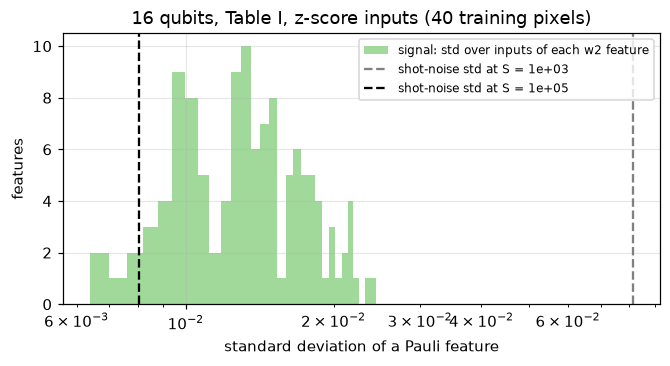

median signal std 0.014; shot-noise std 0.0081 at 1e5 shots


In [8]:
arch16 = architecture_from_config(cfg_data["reservoir"])
reservoir16 = build_reservoir(arch16, hyper, 0, "cpu", torch.float64)
sample_inputs = split0.train_x[:40]
rdms16 = simulate_pair_rdms(reservoir16, sample_inputs, arch16.disjoint_pairs(), chunk_size=40)
probs16 = pair_povm_probabilities(rdms16)
print("input", sample_inputs.shape, "-> pair RDMs", rdms16.shape, "-> POVM probabilities", probs16.shape)

paulis16 = pauli_expectations_from_rdms(rdms16, TWO_QUBIT_PAULIS).reshape(40, -1)   # 8 pairs x 15
spread = paulis16.std(axis=0)                                  # input-to-input signal
shot_sd = {S: shadow_pair_paulis(sample_pair_frequencies(probs16, S, np.random.default_rng(1)),
                                 TWO_QUBIT_PAULIS).reshape(40, -1).__sub__(paulis16).std()
           for S in (1_000, 100_000)}
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(spread, bins=30, color=COLORS["qubit N=16 (z-score)"], label="signal: std over inputs of each w2 feature")
for S, sd in shot_sd.items():
    ax.axvline(sd, ls="--", color="k" if S == 100_000 else "grey", label=f"shot-noise std at S = {S:.0e}")
ax.set_xscale("log"); ax.set_xlabel("standard deviation of a Pauli feature"); ax.set_ylabel("features")
ax.set_title("16 qubits, Table I, z-score inputs (40 training pixels)"); ax.legend(fontsize=8)
plt.show()
print(f"median signal std {np.median(spread):.3f}; shot-noise std {shot_sd[100_000]:.4f} at 1e5 shots")

**Observation.** At 1e3 shots the shot noise is larger than the input-to-input signal of most
features; at 1e5 shots it falls below the signal of most of them, but not by a wide margin.

**Inference.** Landsat accuracy at 1e5 shots should be *shot-noise limited*. §9.3 tests this
directly with an exact-probability control.

## 6. Live experiment: one full-protocol Landsat realisation and NARMA at 8 qubits

*(reproduction, live)* This runs the real experiment code through `runner.train_and_evaluate`,
the same entry point as `implementation.py`, with the **full-run configuration**
(`landsat_readouts_reduced_n16_standard.json`: 16 qubits, 36 layers, 1e5 shots, float64), but
restricted to **one realisation** (split 0, reservoir 0, shot seed 0) and minimal sweeps. Because
the pipeline is seeded, its 16 headline F1 values must equal the stored full run's values for the
same seeds; that confirms the stored results come from this code. About 2–3 minutes.

In [9]:
ONE_REALISATION = {
    "landsat_readouts": {
        "split_seeds": [0], "reservoir_seeds": [0], "shot_seeds": [0],
        "cutoff_sweep": {"cutoffs": [1.0], "readouts": ["w2_etcut_scaled"]},
        "train_size_sweep": {"sizes": [688], "resamples": 1, "readout": "w1_pauli_scaled"},
        "shots_sweep": {"shots": [100000], "readout": "w1_pauli_scaled"},
        "save_probabilities": True,
    }
}
cfg_live = make_config("landsat_readouts_reduced_n16_standard.json", ONE_REALISATION)
print({k: cfg_live["reservoir"][k] for k in ("n_qubits", "n_layers", "input_shift")},
      "| shots", cfg_live["landsat_readouts"]["headline_shots"], "| dtype", cfg_live["dtype"],
      "| input_scaling", cfg_live["dataset"]["landsat"]["input_scaling"])
live_metrics, live_dir = run_live(cfg_live, "landsat_n16_standard_split0_res0")

{'n_qubits': 16, 'n_layers': 36, 'input_shift': 8} | shots 100000 | dtype DtypeSpec(label='float64', torch=torch.float64) | input_scaling standard


landsat_n16_standard_split0_res0: COMPLETED in 158 s -> outdir/notebook/landsat_n16_standard_split0_res0_20261029-090310


In [10]:
def compare_with_stored(live_metrics, system):
    live = pd.DataFrame([r for r in live_metrics["records"] if r["analysis"] == "readouts"])
    stored = frame("landsat_qelm", system)
    stored = stored[(stored.split_seed == 0) & (stored.reservoir_seed == 0) & (stored.shot_seed == 0)]
    table = live.set_index("readout")[["n_features", "f1_macro"]].rename(
        columns={"n_features": "features", "f1_macro": "F1 live"})
    table["F1 stored full run"] = stored.set_index("readout")["f1_macro"]
    table["|difference|"] = (table["F1 live"] - table["F1 stored full run"]).abs()
    return table

live_table = compare_with_stored(live_metrics, "qubit N=16 (z-score)")
print("max |live - stored| =", live_table["|difference|"].max())
live_table

max |live - stored| = 0.0


,features,F1 live,F1 stored full run,|difference|
readout,,,,
w1_x_unit,16,0.646,0.646,0.0
w1_x_scaled,16,0.647,0.647,0.0
w1_pauli_unit,48,0.742,0.742,0.0
w1_pauli_scaled,48,0.732,0.732,0.0
w1_et_unit,48,0.732,0.732,0.0
w1_et_scaled,48,0.732,0.732,0.0
w1_etcut_unit,48,0.732,0.732,0.0
w1_etcut_scaled,48,0.732,0.732,0.0
w2_x_unit,24,0.678,0.678,0.0


**Observation.** The live realisation reproduces all 16 stored F1 values for these seeds.
One realisation is a single draw, though: the spread over the 45 evaluations
(std ≈ 0.03) is larger than most differences between readouts, so conclusions come from the
full records in §7–§10, not from this table.

Next, NARMA at 8 qubits, live, for 5 sequences and reservoir 0 (about 1 minute).

In [11]:
cfg_narma_live = make_config("narma_scaling_reduced_n8.json", {"narma_scaling": {"reservoir_seeds": [0]}})
narma_metrics, _ = run_live(cfg_narma_live, "narma_n8_res0")
live_narma = pd.DataFrame(narma_metrics["records"])
stored_narma = pd.DataFrame(EVIDENCE["narma"]["qubit N=8"]["records"], columns=EVIDENCE["narma"]["qubit N=8"]["columns"])
# Baselines have no reservoir (seed None); QELM records are compared for reservoir 0 only.
stored_narma = stored_narma[stored_narma.reservoir_seed.isna() | (stored_narma.reservoir_seed == 0)]
key = ["model", "condition", "sequence_seed"]
merged = live_narma.merge(stored_narma, on=key, suffixes=(" live", " stored"))
assert len(merged) == len(live_narma) == 35
print("records compared:", len(merged), "| max |cumulative R2 live - stored| =",
      float((merged["cumulative_r2 live"] - merged["cumulative_r2 stored"]).abs().max()))
merged.groupby(["model", "condition"])[["cumulative_r2 live", "cumulative_r2 stored"]].mean()

narma_n8_res0: COMPLETED in 48 s -> outdir/notebook/narma_n8_res0_20261029-090549
records compared: 35 | max |cumulative R2 live - stored| = 0.0


cumulative_r2 live  cumulative_r2 stored
model          condition                                                     
degree2_window none                               3.922                 3.922
esn            none                               4.000                 4.000
matched_elm    none                               3.912                 3.912
qelm           exact                              3.920                 3.920
               gaussian_std_10^-1.5               3.626                 3.626
               shadow_1e5_shots                   3.865                 3.865
raw_window     none                               3.445                 3.445

## 7. Headline reproduction results (stored full runs)

All numbers below are recomputed here from the individual records in
`results/notebook_evidence.json` and checked against the stored summaries.

### 7.1 Operating regime (C1, Fig. 2) — reproduction at the paper's sizes

One NSGA-II search per size (500 trials, 10 reservoir realisations per trial), with Table I
enqueued as trial 0. **Rule declared before launch:** Table I is "near the front" when its Pareto
rank is ≤ 1 or its normalised distance to the front is ≤ 0.1. Both objectives of each projection
are shown, so the trade-off is visible.

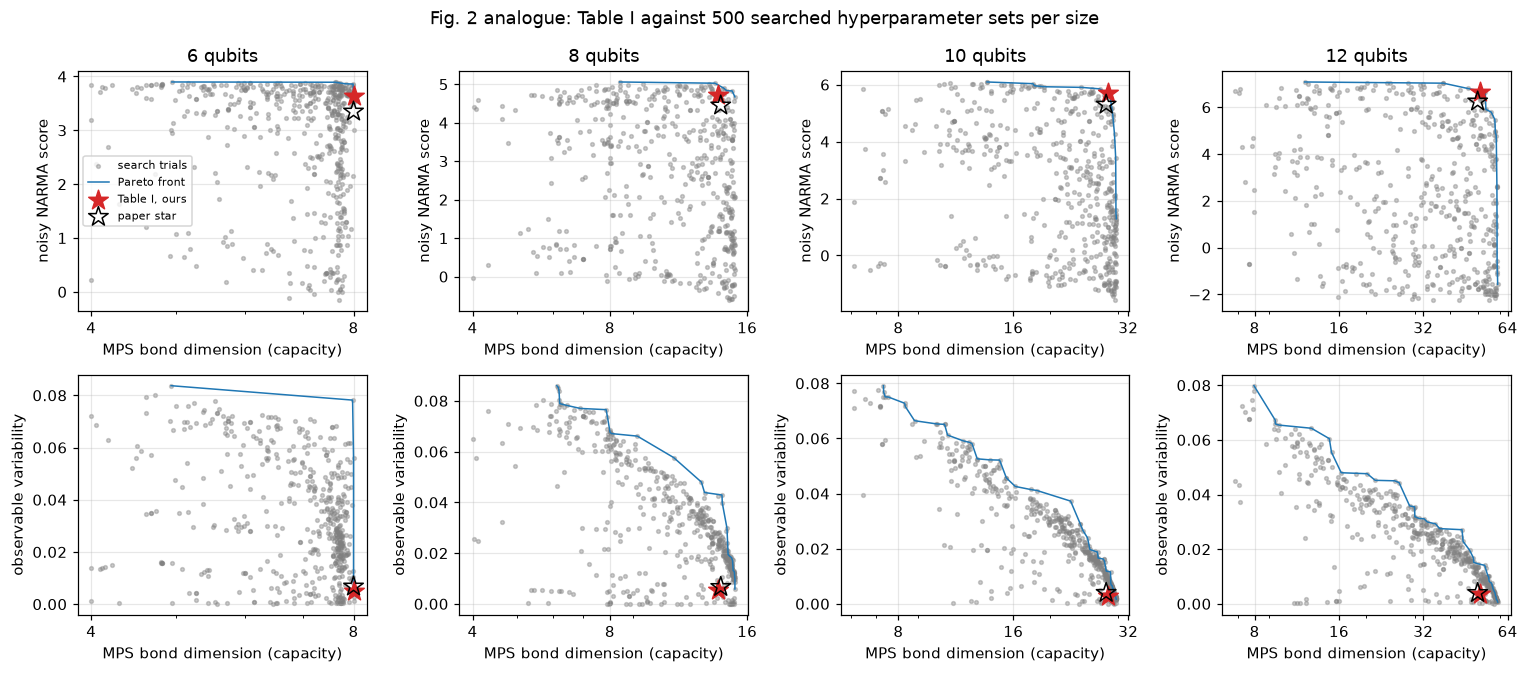

In [12]:
PAPER_STARS = {6: (3.35, 8, 6.8e-3), 8: (4.45, 14, 6.7e-3), 10: (5.3, 28, 4.0e-3), 12: (6.25, 50, 4.0e-3)}

def pareto_front(x, y):
    # Points not dominated when maximising both x and y.
    order = np.argsort(-x)
    front, best_y = [], -np.inf
    for i in order:
        if y[i] > best_y:
            front.append(i); best_y = y[i]
    return np.array(front)

fig, axes = plt.subplots(2, 4, figsize=(14, 6.2))
for col, (n, block) in enumerate(EVIDENCE["pareto"].items()):
    trials = pd.DataFrame(block["trials"], columns=block["columns"])
    star = trials[trials.is_table_I].iloc[0]
    for row, yname in enumerate(["narma_noisy", "variability"]):
        ax = axes[row, col]
        x, y = trials.bond_dimension.to_numpy(), trials[yname].to_numpy()
        ax.scatter(x, y, s=6, color="grey", alpha=0.4, label="search trials")
        front = pareto_front(x, y)
        ax.plot(x[front], y[front], "-", color="tab:blue", lw=1, label="Pareto front")
        ax.scatter(star.bond_dimension, star[yname], marker="*", s=180, color="tab:red", label="Table I, ours", zorder=5)
        paper_y = PAPER_STARS[int(n)][0 if row == 0 else 2]
        ax.scatter(PAPER_STARS[int(n)][1], paper_y, marker="*", s=180, facecolor="none",
                   edgecolor="k", label="paper star", zorder=5)
        ax.set_xscale("log")
        ax.xaxis.set_minor_formatter(plt.NullFormatter())
        ax.xaxis.set_major_formatter(plt.ScalarFormatter())
        ax.set_xticks([t for t in (4, 8, 16, 32, 64) if x.min() * 0.9 <= t <= x.max() * 1.1])
        ax.set_title(f"{n} qubits" if row == 0 else "")
        ax.set_xlabel("MPS bond dimension (capacity)")
        ax.set_ylabel("noisy NARMA score" if row == 0 else "observable variability")
axes[0, 0].legend(fontsize=7)
fig.suptitle("Fig. 2 analogue: Table I against 500 searched hyperparameter sets per size")
plt.tight_layout(); plt.show()

In [13]:
verification = json.loads((PAPER_DIR / "results" / "phase3_selection_verification.json").read_text())["e1_pareto"]
rows = []
for entry in verification:
    proj = entry["projections"]
    rows.append({
        "qubits": entry["n_qubits"], "trials": f'{entry["n_trials_metrics"]}/{entry["n_trials_config"]}',
        "Fig. 2a rank, distance": f'{proj["fig2a_narma_noisy_vs_bond"]["rank"]}, {proj["fig2a_narma_noisy_vs_bond"]["front_distance"]:.3f}',
        "Fig. 2b rank, distance": f'{proj["fig2b_variability_vs_bond"]["rank"]}, {proj["fig2b_variability_vs_bond"]["front_distance"]:.3f}',
        "4-objective rank": proj["all_objectives"]["rank"],
        "near both fronts (rule)": all(p["rank"] <= 1 or p["front_distance"] <= 0.1
                                       for k, p in proj.items() if k != "all_objectives"),
    })
pd.DataFrame(rows).set_index("qubits")

,trials,"Fig. 2a rank, distance","Fig. 2b rank, distance",4-objective rank,near both fronts (rule)
qubits,,,,,
6,500/500,"0, 0.000","1, 0.609",0,True
8,500/500,"3, 0.050","12, 0.112",0,False
10,500/500,"0, 0.000","10, 0.045",0,True
12,500/500,"1, 0.041","8, 0.093",0,True


**Observation.** Table I is non-dominated in the full 4-objective space at every size and
near the Fig. 2a front everywhere. Against the Fig. 2b front it is near at 6, 10 and 12 qubits
but misses at 8 qubits (distance 0.112 against the 0.1 rule). Our Table I objective values are
close to the paper's stars (bond dimension within 1; NARMA score 6–9 % higher; variability
10–25 % lower).

**Inference.** Table I is a genuine trade-off point of the three objectives, not the single-task
optimum: the NARMA-only best trial scores 0.3–0.4 higher (`results/pareto_summary.md`).

**Remaining uncertainty.** One search seed per size; our search ranges and budget are our own
choices (the paper does not state them).

**Claim impact — C1: reproduced** (except the 8-qubit Fig. 2b projection, narrowly).

### 7.2 NARMA memory and transfer (C2, C7, Fig. 3a) — reproduction at reduced size

Table I is used unchanged at 8–24 qubits. Thin lines are individual (sequence, reservoir)
evaluations; the dashed line marks the window $L = N/2$.

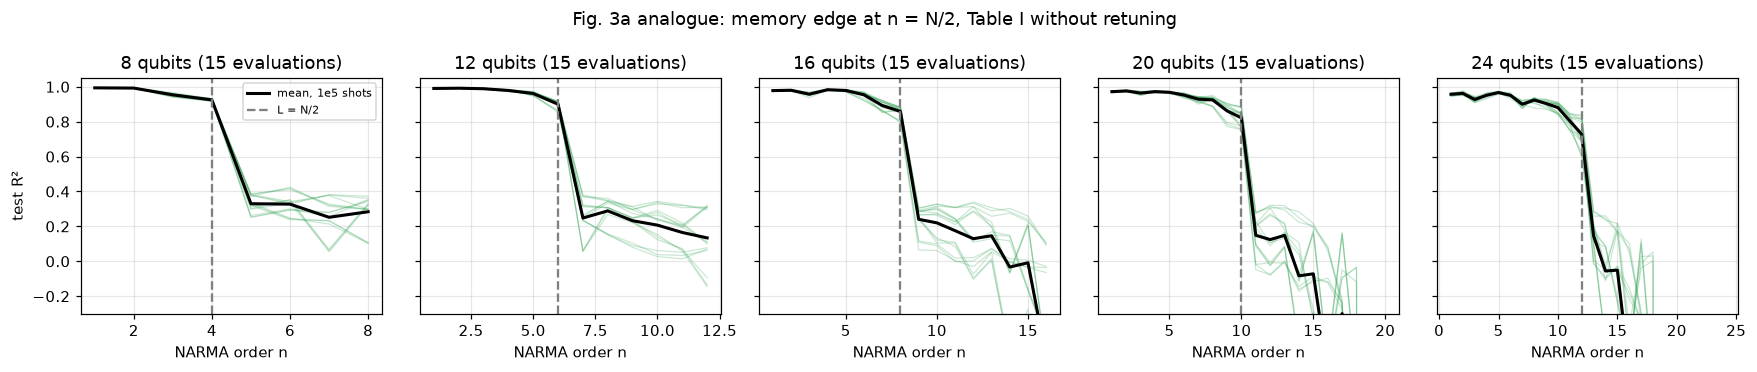

,evaluations,R2 at n = L,R2 at n = L + 1,cumulative R2 (n = 1..L)
qubits,,,,
8,15,0.925,0.330,3.865
12,15,0.900,0.248,5.812
16,15,0.859,0.241,7.583
20,15,0.822,0.149,9.344
24,15,0.728,0.146,10.858


In [14]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.4), sharey=True)
narma_rows = []
for ax, n in zip(axes, (8, 12, 16, 20, 24)):
    block = EVIDENCE["narma"][f"qubit N={n}"]
    records = pd.DataFrame(block["records"], columns=block["columns"])
    shots = records[(records.model == "qelm") & (records.condition == "shadow_1e5_shots")]
    curves = np.array(shots.r2_per_order.tolist())
    orders = np.array(block["orders"])
    for curve in curves:
        ax.plot(orders, curve, color=COLORS["qubit N=24 (z-score)"], alpha=0.25, lw=0.8)
    ax.plot(orders, curves.mean(axis=0), color="k", lw=2, label="mean, 1e5 shots")
    ax.axvline(block["window"], ls="--", color="grey", label="L = N/2")
    ax.set_ylim(-0.3, 1.05); ax.set_xlabel("NARMA order n"); ax.set_title(f"{n} qubits ({len(curves)} evaluations)")
    L = block["window"]
    narma_rows.append({"qubits": n, "evaluations": len(curves),
                       "R2 at n = L": curves[:, L - 1].mean(), "R2 at n = L + 1": curves[:, L].mean(),
                       "cumulative R2 (n = 1..L)": shots.cumulative_r2.mean()})
axes[0].set_ylabel("test R²"); axes[0].legend(fontsize=7)
plt.suptitle("Fig. 3a analogue: memory edge at n = N/2, Table I without retuning"); plt.tight_layout(); plt.show()
narma_table = pd.DataFrame(narma_rows).set_index("qubits")
narma_table

**Observation.** At every size R² stays high up to $n = L$ and then drops sharply (at 24 qubits
from 0.73 to 0.15). The paper's 24-qubit hardware curve is 0.85–0.97 for $n \le 12$ and 0.2–0.45
beyond; ours is 0.73–0.97, then 0.15 and below.

**Inference.** The memory edge follows the window $L = N/2$, as the paper says. That is partly
structural: the readout only sees $L$ inputs, so no model restricted to this window can do better
(§8 compares models on that same window).

**Remaining uncertainty.** Simulation without hardware noise; the 72-qubit hardware curve cannot
be reproduced exactly.

**Claim impact — C7: reproduced; C2 (transfer across sizes without retuning): reproduced
up to 24 qubits.**

### 7.3 Landsat F1 (C4 headline, Fig. 4) — reproduction at 16 and 24 qubits

In [15]:
PAPER_SCALED = {"w1_x_scaled": 0.782, "w1_pauli_scaled": 0.800, "w1_et_scaled": 0.812,
                "w2_x_scaled": 0.789, "w2_pauli_scaled": 0.789, "w2_et_scaled": 0.801,
                "w2_etcut_scaled": 0.830}
SUMMARY_FILES = {"qubit N=16 (min-max)": "landsat_n16_summary.json", "qubit N=24 (min-max)": "landsat_n24_summary.json",
                 "qubit N=16 (z-score)": "landsat_n16_standard_summary.json",
                 "qubit N=24 (z-score)": "landsat_n24_standard_summary.json"}
QELM = pd.concat([frame("landsat_qelm", s) for s in EVIDENCE["landsat_qelm"]], ignore_index=True)

table = {}
for system in QUBIT_SYSTEMS:
    stored = json.loads((PAPER_DIR / "results" / SUMMARY_FILES[system]).read_text())["qelm"]["readouts"]
    column = {}
    for readout in PAPER_SCALED:
        values = QELM[(QELM.system == system) & (QELM.readout == readout)].f1_macro
        assert len(values) == 45
        # The README numbers come from these summaries; they must equal the per-seed means.
        assert abs(values.mean() - stored[readout]["f1_macro"]["mean"]) < 1e-12
        column[readout] = mean_std(values)
    table[system] = column
headline = pd.DataFrame(table)
headline["paper (124 q, 1 run)"] = pd.Series(PAPER_SCALED)
print("F1 macro, mean ± std over 45 evaluations (5 splits x 3 reservoirs x 3 shot draws); "
      "per-seed means match the stored summaries")
headline

F1 macro, mean ± std over 45 evaluations (5 splits x 3 reservoirs x 3 shot draws); per-seed means match the stored summaries


,qubit N=16 (min-max),qubit N=24 (min-max),qubit N=16 (z-score),qubit N=24 (z-score),"paper (124 q, 1 run)"
w1_x_scaled,0.629 ± 0.038,0.690 ± 0.032,0.661 ± 0.044,0.725 ± 0.033,0.782
w1_pauli_scaled,0.715 ± 0.039,0.734 ± 0.031,0.775 ± 0.030,0.785 ± 0.029,0.800
w1_et_scaled,0.719 ± 0.040,0.737 ± 0.030,0.776 ± 0.031,0.788 ± 0.029,0.812
w2_x_scaled,0.656 ± 0.042,0.713 ± 0.033,0.710 ± 0.037,0.754 ± 0.032,0.789
w2_pauli_scaled,0.720 ± 0.039,0.739 ± 0.030,0.791 ± 0.035,0.807 ± 0.030,0.789
w2_et_scaled,0.720 ± 0.038,0.741 ± 0.033,0.791 ± 0.032,0.804 ± 0.031,0.801
w2_etcut_scaled,0.706 ± 0.036,0.731 ± 0.033,0.787 ± 0.032,0.802 ± 0.034,0.830


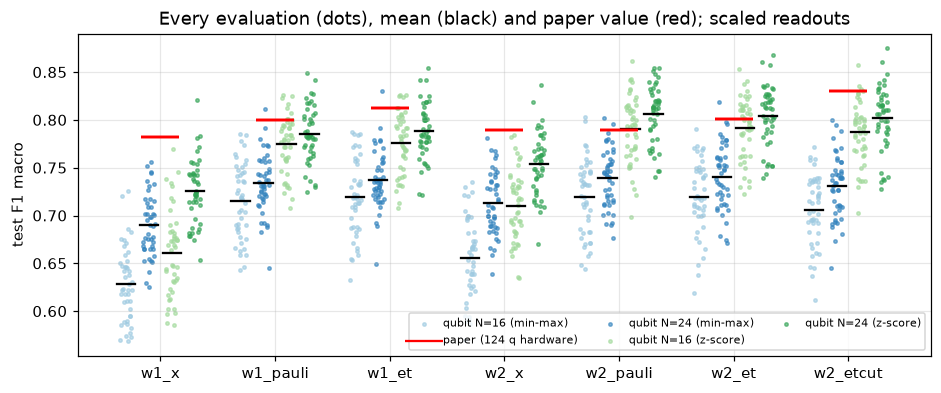

In [16]:
fig, ax = plt.subplots(figsize=(10, 3.8))
readouts = list(PAPER_SCALED)
width = 0.2
for k, system in enumerate(QUBIT_SYSTEMS):
    for i, readout in enumerate(readouts):
        values = QELM[(QELM.system == system) & (QELM.readout == readout)].f1_macro.to_numpy()
        x = i + (k - 1.5) * width + np.random.default_rng(i).uniform(-0.05, 0.05, len(values))
        ax.scatter(x, values, s=5, color=COLORS[system], alpha=0.6, label=system if i == 0 else None)
        ax.plot([i + (k - 1.5) * width - 0.08, i + (k - 1.5) * width + 0.08], [values.mean()] * 2, color="k", lw=1.5)
    ax.scatter(range(len(readouts)), [PAPER_SCALED[r] for r in readouts], marker="_", s=600, color="red",
               label="paper (124 q hardware)" if k == 0 else None, zorder=5)
ax.set_xticks(range(len(readouts))); ax.set_xticklabels([r.replace("_scaled", "") for r in readouts])
ax.set_ylabel("test F1 macro"); ax.set_title("Every evaluation (dots), mean (black) and paper value (red); scaled readouts")
ax.legend(fontsize=7, ncol=3, loc="lower right"); plt.show()

**Observation.** With the pre-declared min-max inputs the QELM sits 0.05–0.15 below the paper (0.05–0.10 at 24 qubits).
With z-score inputs at 24 qubits it reaches 0.79–0.81 for the Pauli and eigentask readouts, at or
just under the paper's 0.80–0.83, and above it for w2 Pauli. The `x` readouts stay 0.03–0.06 below.
The spread over seeds (std ≈ 0.03) is as large as the gaps between readouts.

**Inference.** The paper's headline accuracy is reachable at 24 qubits once the inputs are
z-scored. §9.3 shows the min-max gap comes from shot noise, not from a pipeline error.

**Remaining uncertainty.** The paper's subset and input scaling are unpublished; it reports one
hardware run on one split.

**Claim impact — C4 accuracy level: reproduced with z-score inputs.** Whether this is
"competitive" is tested against matched baselines in §8.

### 7.4 Shots and training size (C5, Fig. 3b/3c) — reproduction

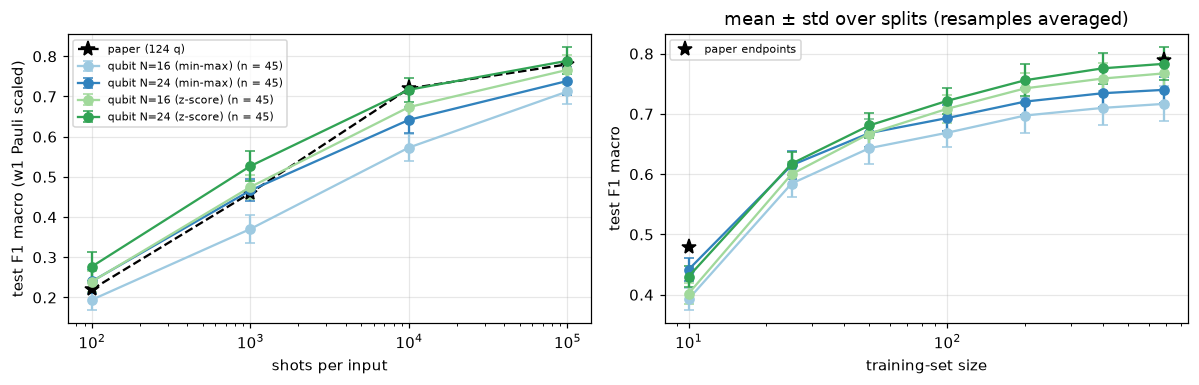

In [17]:
PAPER_SHOTS = {100: 0.22, 1_000: 0.46, 10_000: 0.72, 100_000: 0.78}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for system in QUBIT_SYSTEMS:
    shots = frame("landsat_qelm", system, "shots")
    curve = shots.groupby("shots").f1_macro.agg(["mean", "std", "count"])
    axes[0].errorbar(curve.index, curve["mean"], yerr=curve["std"], marker="o", capsize=3,
                     color=COLORS[system], label=f"{system} (n = {curve['count'].iloc[0]})")
    sizes = frame("landsat_qelm", system, "train_size").groupby("train_size").f1_macro_mean.agg(["mean", "std"])
    axes[1].errorbar(sizes.index, sizes["mean"], yerr=sizes["std"], marker="o", capsize=3, color=COLORS[system])
axes[0].plot(list(PAPER_SHOTS), list(PAPER_SHOTS.values()), "k*--", ms=10, label="paper (124 q)")
axes[0].set_xscale("log"); axes[0].set_xlabel("shots per input"); axes[0].set_ylabel("test F1 macro (w1 Pauli scaled)")
axes[0].legend(fontsize=7)
axes[1].plot([10, 690], [0.48, 0.79], "k*", ms=10, label="paper endpoints")
axes[1].set_xscale("log"); axes[1].set_xlabel("training-set size"); axes[1].set_ylabel("test F1 macro")
axes[1].legend(fontsize=7); axes[1].set_title("mean ± std over splits (resamples averaged)")
plt.tight_layout(); plt.show()

**Observation.** F1 rises monotonically with shots and with training size for every system. With
z-score inputs at 24 qubits the shot curve matches the paper's within 0.07 at every point and within 0.01
at 1e4–1e5 shots; it is still rising at the largest training size.

**Claim impact — C5: reproduced** (trend and, with z-score inputs, level).

## 8. Fair baseline comparison (extension; protocol frozen before the run)

The paper's Landsat baselines are untuned scikit-learn models that see the **36 raw features**,
while the QELM's ridge sees **48–930 reservoir features**. That compares feature maps of very
different size. The fair control planned in Phase 1 keeps everything but the feature map fixed: a
**random-feature map** (random Fourier $\cos(Wx+c)$ or tanh $\tanh(Wx+c)$, plus feature noise 0.01
to mimic finite shots) with **the same output dimension**, fed into the **same ridge readout**.

| Fairness axis | QELM | Matched random features | Matched? |
|---|---|---|---|
| Information and inputs | the 36 scaled Landsat features (tiled ×2) | the same 36 scaled features, same scaling | yes |
| Feature dimension (= trained parameters, 6 × d + 6) | d = 3N (w1), 15N/2 (w2) | the same d | **yes** |
| Training data | 688 rows, same split seeds | same | yes |
| Optimisation | closed-form ridge, α by leave-one-out on train | identical function and α grid | yes |
| Tuning budget | none on the reservoir (Table I fixed) | none on the map (bandwidth 2.0, tanh scale 1.0, fixed earlier) | yes, both untuned (see caveat) |
| Compute / wall time | 30 min (16 q, laptop) to 18 h (24 q, L4 GPU), simulation | 7–8 min for all baselines, laptop | **no**; simulation cost is not hardware cost |
| Evaluation protocol | test F1 macro, 5 splits | the same 5 splits | yes |

**Decision rule (frozen before the baseline run).** Average each system over its
evaluations within a split, take the paired difference over the 5 splits, and call one system
"clearly above" when the mean difference exceeds the tie margin (0.01 F1; for NARMA, 1 % of the
baseline) **and** 2 standard errors. Primary baseline: random Fourier features with noise 0.01;
the tanh family is reported too.

In [18]:
TIE = 0.01

def paired_verdict(qelm_by_split, base_by_split, tie):
    keys = sorted(qelm_by_split)
    diff = np.array([qelm_by_split[k] - base_by_split[k] for k in keys])
    mean, stderr = diff.mean(), diff.std(ddof=1) / np.sqrt(len(diff))
    if mean > tie and mean > 2 * stderr:
        verdict = "QELM clearly above"
    elif -mean > tie and -mean > 2 * stderr:
        verdict = "baseline clearly above"
    else:
        verdict = "no clear separation"
    return diff, mean, stderr, verdict

PRIMARY = {"qubit": ["w1_et_scaled", "w2_et_scaled"], "photonic": ["w1_et_scaled", "w2_et_scaled"]}
stored_verdicts = {(e["system"], e["readout"]): e for e in PHASE5["landsat"]}
rows, per_split = [], []
for system in EVIDENCE["landsat_qelm"]:
    scaling = "minmax" if "min-max" in system else "standard"
    classical = EVIDENCE["landsat_classical"][scaling]["f1_macro_per_split"]
    for readout in PRIMARY["qubit"]:
        evals = QELM[(QELM.system == system) & (QELM.readout == readout)]
        qelm_split = evals.groupby("split_seed").f1_macro.mean().to_dict()
        dim = int(evals.n_features.iloc[0])
        for family in ("fourier", "tanh"):
            base = {int(k): v for k, v in classical[f"elm {family}|n_features={dim}|noise_std=0.01"].items()}
            diff, mean, se, verdict = paired_verdict(qelm_split, base, TIE)
            stored = stored_verdicts[(system, readout)]
            stored_verdict = (stored["primary"]["paired"]["verdict"] if family == "fourier"
                              else stored["comparisons"]["tanh|noise=0.01"]["paired"]["verdict"])
            assert verdict == stored_verdict, (system, readout, family)
            rows.append({"system": system, "readout": readout, "features": dim, "baseline": f"{family} (noise 0.01)",
                         "QELM F1": np.mean(list(qelm_split.values())), "baseline F1": np.mean(list(base.values())),
                         "paired diff": mean, "2 SE": 2 * se, "splits QELM > base": int((diff > 0).sum()),
                         "verdict": verdict})
            per_split += [{"system": system, "readout": readout, "family": family, "split": k, "diff": d}
                          for k, d in zip(sorted(qelm_split), diff)]
fair = pd.DataFrame(rows)
print("All 24 verdicts recomputed here equal results/phase5_comparison.json.")
fair.set_index(["system", "readout", "baseline"])

All 24 verdicts recomputed here equal results/phase5_comparison.json.


features  QELM F1  \
system               readout      baseline                                  
qubit N=16 (min-max) w1_et_scaled fourier (noise 0.01)        48    0.719   
                                  tanh (noise 0.01)           48    0.719   
                     w2_et_scaled fourier (noise 0.01)       120    0.720   
                                  tanh (noise 0.01)          120    0.720   
qubit N=24 (min-max) w1_et_scaled fourier (noise 0.01)        72    0.737   
                                  tanh (noise 0.01)           72    0.737   
                     w2_et_scaled fourier (noise 0.01)       180    0.741   
                                  tanh (noise 0.01)          180    0.741   
qubit N=16 (z-score) w1_et_scaled fourier (noise 0.01)        48    0.776   
                                  tanh (noise 0.01)           48    0.776   
                     w2_et_scaled fourier (noise 0.01)       120    0.791   
                                  tanh (noise 0.01)          120    0.791   
qubit N=24 (z-score) w1_et_scaled fourier (noise 0.01)        72    0.788   
                                  tanh (noise 0.01)           72    0.788   
                     w2_et_scaled fourier (noise 0.01)       180    0.804   
                                  tanh (noise 0.01)          180    0.804   
photonic 16/4        w1_et_scaled fourier (noise 0.01)        16    0.736   
                                  tanh (noise 0.01)           16    0.736   
                     w2_et_scaled fourier (noise 0.01)        24    0.749   
                                  tanh (noise 0.01)           24    0.749   
photonic 24/6        w1_et_scaled fourier (noise 0.01)        24    0.755   
                                  tanh (noise 0.01)           24    0.755   
                     w2_et_scaled fourier (noise 0.01)        36    0.777   
                                  tanh (noise 0.01)           36    0.777   

                                                        baseline F1  \
system               readout      baseline                            
qubit N=16 (min-max) w1_et_scaled fourier (noise 0.01)        0.787   
                                  tanh (noise 0.01)           0.741   
                     w2_et_scaled fourier (noise 0.01)        0.816   
                                  tanh (noise 0.01)           0.781   
qubit N=24 (min-max) w1_et_scaled fourier (noise 0.01)        0.801   
                                  tanh (noise 0.01)           0.764   
                     w2_et_scaled fourier (noise 0.01)        0.831   
                                  tanh (noise 0.01)           0.782   
qubit N=16 (z-score) w1_et_scaled fourier (noise 0.01)        0.750   
                                  tanh (noise 0.01)           0.784   
                     w2_et_scaled fourier (noise 0.01)        0.813   
                                  tanh (noise 0.01)           0.817   
qubit N=24 (z-score) w1_et_scaled fourier (noise 0.01)        0.783   
                                  tanh (noise 0.01)           0.800   
                     w2_et_scaled fourier (noise 0.01)        0.825   
                                  tanh (noise 0.01)           0.829   
photonic 16/4        w1_et_scaled fourier (noise 0.01)        0.601   
                                  tanh (noise 0.01)           0.683   
                     w2_et_scaled fourier (noise 0.01)        0.663   
                                  tanh (noise 0.01)           0.736   
photonic 24/6        w1_et_scaled fourier (noise 0.01)        0.663   
                                  tanh (noise 0.01)           0.736   
                     w2_et_scaled fourier (noise 0.01)        0.723   
                                  tanh (noise 0.01)           0.749   

                                                        paired diff   2 SE  \
system               readout      baseline                                   
qubit N=16 (min-max) w1_et_scaled fourier (noise 0

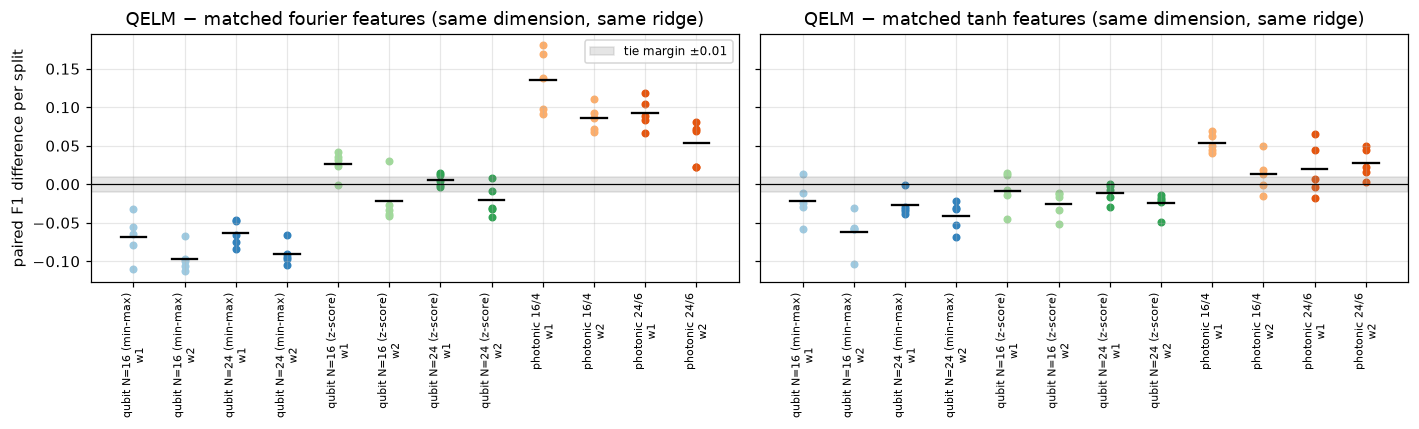

In [19]:
splits = pd.DataFrame(per_split)
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, family in zip(axes, ("fourier", "tanh")):
    labels = []
    for i, ((system, readout), group) in enumerate(splits[splits.family == family].groupby(["system", "readout"], sort=False)):
        ax.scatter([i] * len(group), group["diff"], color=COLORS[system], s=18)
        ax.plot([i - 0.25, i + 0.25], [group["diff"].mean()] * 2, color="k")
        labels.append(f"{system}\n{readout[:2]}")
    ax.axhspan(-TIE, TIE, color="grey", alpha=0.2, label="tie margin ±0.01")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=90, fontsize=7)
    ax.set_title(f"QELM − matched {family} features (same dimension, same ridge)")
axes[0].set_ylabel("paired F1 difference per split"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [20]:
references = EVIDENCE["landsat_classical"]["standard"]["f1_macro_per_split"]
ref_rows = {name: mean_std(list(references[name].values())) for name in
            ["ridge (untuned)", "random_forest (untuned)", "knn (untuned)", "mlp (untuned)", "svm_rbf (untuned)",
             "random_forest (tuned)", "svm_rbf (tuned)", "ridge degree-2"]}
paper_ref = {"ridge (untuned)": 0.608, "random_forest (untuned)": 0.840, "knn (untuned)": 0.834,
             "mlp (untuned)": 0.830, "svm_rbf (untuned)": 0.809}
pd.DataFrame({"ours, 5 splits (raw 36 features)": ref_rows, "paper Fig. 4": pd.Series(paper_ref)})

,"ours, 5 splits (raw 36 features)",paper Fig. 4
knn (untuned),0.810 ± 0.032,0.834
mlp (untuned),0.835 ± 0.024,0.830
random_forest (tuned),0.862 ± 0.030,NaN
random_forest (untuned),0.856 ± 0.026,0.840
ridge (untuned),0.588 ± 0.028,0.608
ridge degree-2,0.749 ± 0.017,NaN
svm_rbf (tuned),0.843 ± 0.027,NaN
svm_rbf (untuned),0.842 ± 0.032,0.809


**Observation (Landsat).**

- Qubit QELM with min-max inputs: the matched random-feature map is clearly above in all 4 cases.
- With z-score inputs it is clearly above in 1 case, ties in 2 and loses in 1 against random
  Fourier features, and against tanh features it ties or loses everywhere.
- Every QELM beats ridge on the raw features (0.59) and trails the tuned random forest (0.86) and
  SVM (0.84).
- Our classical models reproduce the paper's Fig. 4 values within about one split-std.

The MerLin systems clearly beat random Fourier features at their much smaller dimensions (16–36),
but by only 0.01–0.05 against tanh features (§11).

**Inference.** The reservoir does make the classes more linearly separable than the raw inputs,
but a classical random feature map of the same size does at least as well. "Competitive with
classical models" holds only in the weak sense of beating raw-feature ridge.

**Remaining uncertainty.** Both feature maps are untuned. The random-feature bandwidth was set
for min-max inputs and kept for z-scores, and the tanh family turned out stronger at small
dimensions only after the protocol was frozen, so it is reported but did not replace the primary
rule.

**Claim impact — C4: partially reproduced** (beats raw ridge; not above a matched feature map).

In [21]:
narma_rows = []
for label in ["qubit N=16", "qubit N=24", "photonic 16/4", "photonic 24/6"]:
    block = EVIDENCE["narma"][label]
    rec = pd.DataFrame(block["records"], columns=block["columns"])
    qelm = rec[(rec.model == "qelm") & rec.condition.isin(["shadow_1e5_shots", "shots_1e5"])]
    assert len(qelm) == 15
    q_seq = qelm.groupby("sequence_seed").cumulative_r2.mean().to_dict()
    stored = {e["label"]: e for e in PHASE5["narma"]}[label]
    for model in ("raw_window", "degree2_window", "matched_elm", "esn"):
        base = rec[rec.model == model].set_index("sequence_seed").cumulative_r2.to_dict()
        tie = 0.01 * abs(np.mean(list(base.values())))
        _, mean, se, verdict = paired_verdict(q_seq, base, tie)
        assert verdict == stored["comparisons"][model]["paired"]["verdict"]
        narma_rows.append({"system": label, "window L": block["window"], "baseline": model,
                           "baseline features": int(rec[rec.model == model].n_features.iloc[0]),
                           "QELM cum. R2": np.mean(list(q_seq.values())), "baseline cum. R2": np.mean(list(base.values())),
                           "paired diff": mean, "verdict": verdict})
pd.DataFrame(narma_rows).set_index(["system", "baseline"])

window L  baseline features  QELM cum. R2  \
system        baseline                                                    
qubit N=16    raw_window             8                  8         7.583   
              degree2_window         8                 44         7.583   
              matched_elm            8                192         7.583   
              esn                    8                400         7.583   
qubit N=24    raw_window            12                 12        10.858   
              degree2_window        12                 90        10.858   
              matched_elm           12                288        10.858   
              esn                   12                400        10.858   
photonic 16/4 raw_window             8                  8         7.000   
              degree2_window         8                 44         7.000   
              matched_elm            8                 31         7.000   
              esn                    8                400         7.000   
photonic 24/6 raw_window            12                 12         9.875   
              degree2_window        12                 90         9.875   
              matched_elm           12                 47         9.875   
              esn                   12                400         9.875   

                              baseline cum. R2  paired diff  \
system        baseline                                        
qubit N=16    raw_window                 6.766        0.817   
              degree2_window             7.796       -0.213   
              matched_elm                7.708       -0.125   
              esn                        7.955       -0.372   
qubit N=24    raw_window                 9.923        0.935   
              degree2_window            11.321       -0.463   
              matched_elm               11.123       -0.265   
              esn                       11.530       -0.672   
photonic 16/4 raw_window                 6.766        0.234   
              degree2_window             7.796       -0.795   
              matched_elm                7.146       -0.145   
              esn                        7.955       -0.955   
photonic 24/6 raw_window                 9.923       -0.048   
              degree2_window            11.321       -1.446   
              matched_elm               10.063       -0.188   
              esn                       11.530       -1.655   

                                             verdict  
system        baseline                                
qubit N=16    raw_window          QELM clearly above  
              degree2_window  baseline clearly above  
              matched_elm     baseline clearly above  
              esn             baseline clearly above  
qubit N=24    raw_window          QELM clearly above  
              degree2_window  baseline clearly above  
              matched_elm     baseline clearly above  
              esn             baseline clearly above  
photonic 16/4 raw_window          QELM clearly above  
              degree2_window  baseline clearly above  
              matched_elm     baseline clearly above  
              esn             baseline clearly above  
photonic 24/6 raw_window         no clear separation  
              degree2_window  baseline clearly above  
              matched_elm     baseline clearly above  
              esn             baseline clearly above

**Observation (NARMA, same sequences and window).** Every QELM is clearly above ridge on the raw
window (except MerLin 24/6, which ties it), and clearly *below* a tanh random-feature map of the
same dimension, ridge on degree-2 window features, and a 400-unit echo-state network (which has
real memory and is a reference only).

**Claim impact.** C2/C7 (transfer, memory edge) stand, but with no accuracy advantage over simple
classical models on the same window.

## 9. Controls and ablations

### 9.1 Do eigentasks and NSR scaling help? (C3) — control

The paper's readout gains are differences between readouts on **the same** measurements, so the
right test is a **paired** difference on identical (split, reservoir, shot) seeds. To avoid
treating the 45 correlated evaluations as independent, uncertainty uses the 5 split means
(SE over splits).

In [22]:
CONTRASTS = {
    "w1: ET − Pauli (scaled)": ("w1_et_scaled", "w1_pauli_scaled", 0.812 - 0.800),
    "w2: ET − Pauli (scaled)": ("w2_et_scaled", "w2_pauli_scaled", 0.801 - 0.789),
    "w2: ET-cut − ET (scaled)": ("w2_etcut_scaled", "w2_et_scaled", 0.830 - 0.801),
    "w2: ET scaled − unit": ("w2_et_scaled", "w2_et_unit", 0.801 - 0.749),
    "w1: Pauli scaled − unit": ("w1_pauli_scaled", "w1_pauli_unit", 0.800 - 0.790),
}
rows, dists = [], []
for system in QUBIT_SYSTEMS:
    wide = QELM[QELM.system == system].pivot_table(index=["split_seed", "reservoir_seed", "shot_seed"],
                                                   columns="readout", values="f1_macro")
    for name, (a, b, paper) in CONTRASTS.items():
        diff = wide[a] - wide[b]
        by_split = diff.groupby(level="split_seed").mean()
        rows.append({"system": system, "contrast": name, "paper (1 run)": paper, "ours mean": diff.mean(),
                     "SE (over 5 splits)": by_split.std(ddof=1) / np.sqrt(5), "evaluations > 0": f"{(diff > 0).sum()}/45"})
        dists.append(diff.to_numpy())
contrasts = pd.DataFrame(rows)
contrasts.pivot(index="contrast", columns="system", values="ours mean").assign(
    paper=pd.Series({k: v[2] for k, v in CONTRASTS.items()}))

system,qubit N=16 (min-max),qubit N=16 (z-score),qubit N=24 (min-max),qubit N=24 (z-score),paper
contrast,,,,,
w1: ET − Pauli (scaled),3.749e-03,1.011e-03,0.004,0.003,0.012
w1: Pauli scaled − unit,-3.933e-03,-1.381e-03,0.003,-0.004,0.010
w2: ET scaled − unit,-1.601e-02,-4.108e-03,-0.013,-0.006,0.052
w2: ET − Pauli (scaled),-3.063e-05,5.246e-04,0.001,-0.002,0.012
w2: ET-cut − ET (scaled),-1.346e-02,-4.352e-03,-0.010,-0.003,0.029


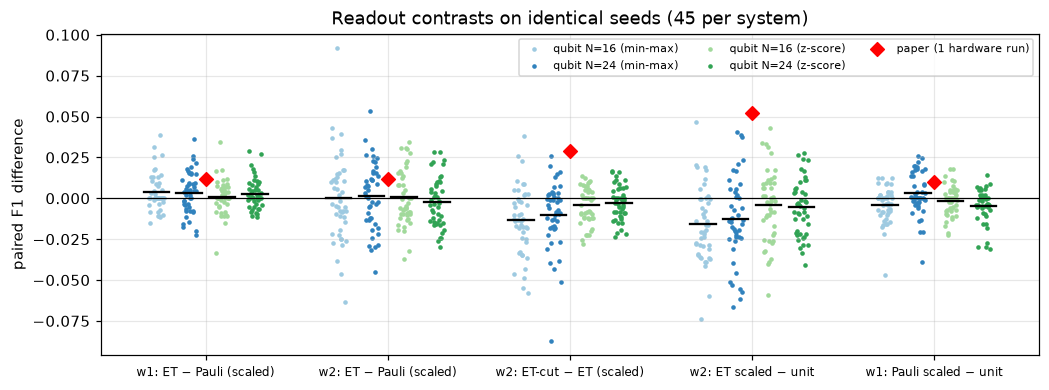

,,paper (1 run),ours mean,SE (over 5 splits),evaluations > 0
contrast,system,,,,
w1: ET − Pauli (scaled),qubit N=16 (min-max),0.012,3.749e-03,1.143e-03,19/45
w2: ET − Pauli (scaled),qubit N=16 (min-max),0.012,-3.063e-05,4.192e-03,21/45
w2: ET-cut − ET (scaled),qubit N=16 (min-max),0.029,-1.346e-02,1.652e-03,11/45
w2: ET scaled − unit,qubit N=16 (min-max),0.052,-1.601e-02,4.315e-03,10/45
w1: Pauli scaled − unit,qubit N=16 (min-max),0.010,-3.933e-03,1.867e-03,15/45
w1: ET − Pauli (scaled),qubit N=24 (min-max),0.012,3.510e-03,2.374e-03,26/45
w2: ET − Pauli (scaled),qubit N=24 (min-max),0.012,1.493e-03,4.471e-03,25/45
w2: ET-cut − ET (scaled),qubit N=24 (min-max),0.029,-9.958e-03,9.971e-04,14/45
w2: ET scaled − unit,qubit N=24 (min-max),0.052,-1.289e-02,5.555e-03,14/45


In [23]:
fig, ax = plt.subplots(figsize=(11, 3.8))
for i, name in enumerate(CONTRASTS):
    for k, system in enumerate(QUBIT_SYSTEMS):
        values = dists[k * len(CONTRASTS) + i]
        x = i + (k - 1.5) * 0.18
        ax.scatter(x + np.random.default_rng(k).uniform(-0.04, 0.04, len(values)), values, s=4, color=COLORS[system],
                   label=system if i == 0 else None)
        ax.plot([x - 0.07, x + 0.07], [values.mean()] * 2, color="k")
    ax.scatter(i, CONTRASTS[name][2], marker="D", color="red", s=40, zorder=5, label="paper (1 hardware run)" if i == 0 else None)
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(range(len(CONTRASTS))); ax.set_xticklabels(CONTRASTS, fontsize=8)
ax.set_ylabel("paired F1 difference"); ax.legend(fontsize=7, ncol=3); ax.set_title("Readout contrasts on identical seeds (45 per system)")
plt.show()
contrasts.set_index(["contrast", "system"])

**Observation.**

- Eigentask − Pauli is within ±0.004 of zero in every system, against the paper's +0.012.
- The NSR cutoff never helps (−0.003 to −0.013, against the paper's +0.029).
- Scaled − unit lies between −0.016 and +0.003, against the paper's +0.01 to +0.05.

All of this holds with both input scalings and at both sizes.

**Inference.** At ≤ 24 qubits with ideal (shot-noise-only) simulation, the eigentask machinery
reorganises the information but does not add usable signal for the linear readout.

**Remaining uncertainty.** The paper's margins come from a single hardware run on one split and
are smaller than our per-evaluation std (about 0.03). Hardware noise, which does not behave like
shot noise, could make NSR-based selection useful at 124 qubits; we cannot test that.

**Claim impact — C3: not reproduced at N ≤ 24.**

### 9.2 NSR cutoff sweep and retained eigentasks (C6, Fig. A3/A4) — control

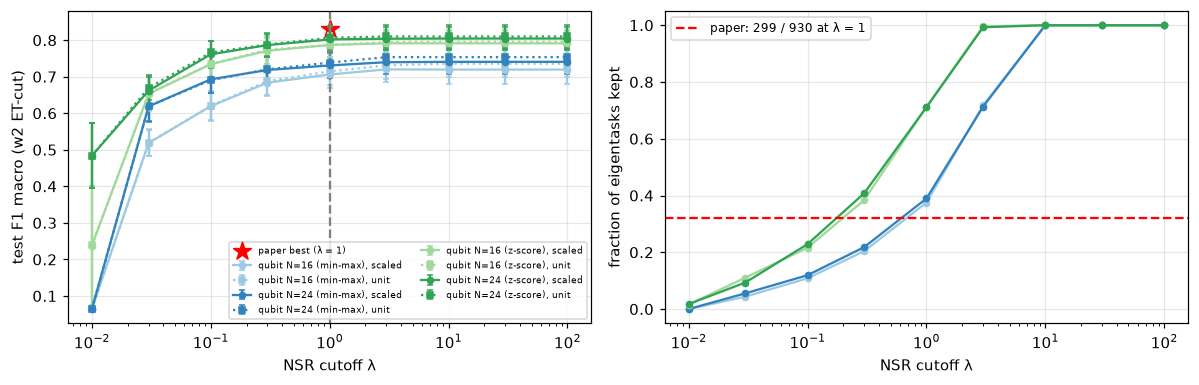

,retained at λ = 1
system,
qubit N=16 (min-max),37.5%
qubit N=24 (min-max),39.0%
qubit N=16 (z-score),71.2%
qubit N=24 (z-score),71.1%


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
retained_rows = []
for system in QUBIT_SYSTEMS:
    cut = frame("landsat_qelm", system, "cutoff")
    for readout, style in (("w2_etcut_scaled", "-o"), ("w2_etcut_unit", ":s")):
        curve = cut[cut.readout == readout].groupby("nsr_cutoff").f1_macro.agg(["mean", "std"])
        axes[0].errorbar(curve.index, curve["mean"], yerr=curve["std"], fmt=style, capsize=2, color=COLORS[system],
                         label=f"{system}, {readout.split('_')[-1]}", ms=4)
    frac = cut[cut.readout == "w2_etcut_scaled"].assign(fraction=lambda d: d.n_retained / d.n_total)
    frac_curve = frac.groupby("nsr_cutoff").fraction.mean()
    axes[1].plot(frac_curve.index, frac_curve.values, "-o", color=COLORS[system], ms=4)
    retained_rows.append({"system": system, "retained at λ = 1": f"{frac_curve.loc[1.0]:.1%}"})
axes[0].axvline(1.0, ls="--", color="grey"); axes[0].scatter([1.0], [0.830], marker="*", s=150, color="red", label="paper best (λ = 1)")
axes[0].set_xscale("log"); axes[0].set_xlabel("NSR cutoff λ"); axes[0].set_ylabel("test F1 macro (w2 ET-cut)")
axes[0].legend(fontsize=6, ncol=2)
axes[1].axhline(299 / 930, color="red", ls="--", label="paper: 299 / 930 at λ = 1")
axes[1].set_xscale("log"); axes[1].set_xlabel("NSR cutoff λ"); axes[1].set_ylabel("fraction of eigentasks kept")
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
pd.DataFrame(retained_rows).set_index("system")

**Observation.** F1 rises monotonically with λ up to "keep everything" in every system. There is
no optimum near λ = 1. The retained fraction at λ = 1 matches the paper with min-max inputs
(37.5 % vs 32 %) but not with z-score inputs (71 %).

**Claim impact — C6: partially reproduced.** The retained count is reproduced (min-max only);
the claimed stability and optimum around λ = 1 are not.

### 9.3 Why is min-max Landsat below the paper? Exact-probability and input-scaling controls

*(control)* Two alternative explanations for the min-max gap are a pipeline or metric error,
and shot noise. If the pipeline were wrong, it would also fail with **exact** probabilities
(infinite shots). The first check is live, on the realisation computed in §6; the second uses the
stored diagnostic runs (15 realisations for min-max).

In [25]:
saved = np.load(next(live_dir.glob("probabilities_split0_res0.npz")))
alphas = alpha_grid(cfg_live["readout"])
rows = []
for readout in ("w1_pauli_unit", "w2_pauli_unit"):
    for shots in (1_000, 10_000, 100_000, None):
        rng = np.random.default_rng([0, 0, 0])
        train_f = saved["train"] if shots is None else sample_pair_frequencies(saved["train"], shots, rng)
        test_f = saved["test"] if shots is None else sample_pair_frequencies(saved["test"], shots, rng)
        tr, te, _ = readout_features(readout, train_f, test_f, shots or 10**9, 1.0)
        result = fit_ridge_classifier(tr, saved["train_y"], te, saved["test_y"], alphas)
        rows.append({"readout": readout, "shots": "exact" if shots is None else f"{shots:.0e}",
                     "test F1": result["f1_macro"], "train F1": result["train_f1_macro"]})
pd.DataFrame(rows).pivot(index="shots", columns="readout", values=["test F1", "train F1"])

test F1                    train F1              
readout w1_pauli_unit w2_pauli_unit w1_pauli_unit w2_pauli_unit
shots                                                          
1e+03           0.426         0.436         0.561         0.706
1e+04           0.641         0.632         0.721         0.823
1e+05           0.742         0.744         0.812         0.868
exact           0.758         0.830         0.824         0.894

In [26]:
rows = []
for scaling, block in EVIDENCE["gap_exact_vs_shots"].items():
    gap = pd.DataFrame(block["records"], columns=block["columns"])
    for readout in ("w1_pauli_unit", "w2_pauli_unit", "w2_pauli_scaled"):
        sub = gap[gap.readout == readout]
        exact, shots = sub[sub.condition == "exact"], sub[sub.condition == "shots_100000"]
        rows.append({"input scaling": scaling, "readout": readout, "realisations": len(exact),
                     "exact test F1": mean_std(exact.f1_macro), "1e5-shot test F1": mean_std(shots.f1_macro),
                     "exact train F1": mean_std(exact.train_f1_macro), "1e5-shot train F1": mean_std(shots.train_f1_macro)})
pd.DataFrame(rows).set_index(["input scaling", "readout"])

realisations  exact test F1 1e5-shot test F1  \
input scaling readout                                                         
minmax        w1_pauli_unit              15  0.787 ± 0.027    0.721 ± 0.039   
              w2_pauli_unit              15  0.820 ± 0.022    0.740 ± 0.033   
              w2_pauli_scaled            15  0.824 ± 0.021    0.720 ± 0.044   
standard      w1_pauli_unit               2  0.761 ± 0.003    0.743 ± 0.000   
              w2_pauli_unit               2  0.830 ± 0.001    0.758 ± 0.014   
              w2_pauli_scaled             2  0.839 ± 0.009    0.745 ± 0.024   

                              exact train F1 1e5-shot train F1  
input scaling readout                                           
minmax        w1_pauli_unit    0.827 ± 0.015     0.763 ± 0.026  
              w2_pauli_unit    0.871 ± 0.012     0.839 ± 0.016  
              w2_pauli_scaled  0.871 ± 0.014     0.803 ± 0.028  
standard      w1_pauli_unit    0.818 ± 0.006     0.803 ± 0.009  
              w2_pauli_unit    0.879 ± 0.015     0.867 ± 0.001  
              w2_pauli_scaled  0.890 ± 0.005     0.840 ± 0.007

**Observation.**

- With exact probabilities the 16-qubit feature map already reaches the paper's F1 (w1 ≈ 0.79,
  w2 ≈ 0.82).
- At 1e5 shots it loses 0.07–0.10 with min-max inputs. With z-score inputs the w1 loss shrinks to
  0.02 and the w2 loss to 0.07–0.09 (2 realisations), and the 1e5-shot F1 is higher in every case.
- Train F1 drops together with test F1, so this is noise-induced underfitting, not overfitting.

**Inference.** The reservoir and readout code are right, and the gap is shot noise. It is set
mainly by the input scale: z-scores give larger input-dependent rotations ($|u|$ up to about 3
against 1), hence more signal per shot. The paper does not state its QELM input scaling.

**Remaining uncertainty.** The z-score diagnostic used 2 realisations; it was then confirmed by
the full 45-evaluation z-score runs in §7.3.

### 9.4 Does Table I avoid concentration? (C8) — control against a scrambling circuit

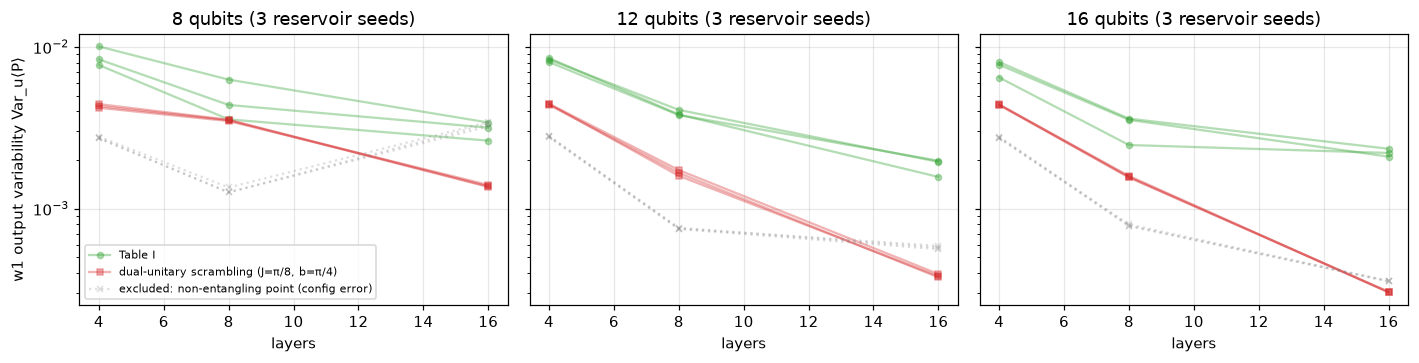

Table I / dual-unitary scrambling variability ratio (w1), by qubits x layers:


layers,4,8,16
n_qubits,,,
8,2.0,1.3,2.2
12,1.9,2.3,4.8
16,1.7,2.0,7.3


In [27]:
conc = pd.DataFrame(EVIDENCE["concentration"]["qubit"]["records"] + EVIDENCE["concentration"]["qubit_scrambling"]["records"])
# The "scrambling" rows of the first run (J = b = pi/4) are NOT a scrambling reference: with two RZZ per block
# and angle_scale 2 the ZZ angle is pi/2, which is non-entangling (E1b). They are shown for transparency only.
conc["label"] = conc.setting.map({"table_I": "Table I", "scrambling_dual_unitary": "dual-unitary scrambling (J=π/8, b=π/4)",
                                  "scrambling": "excluded: non-entangling point (config error)"})
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, n in zip(axes, (8, 12, 16)):
    for label, style in (("Table I", "-o"), ("dual-unitary scrambling (J=π/8, b=π/4)", "-s"),
                         ("excluded: non-entangling point (config error)", ":x")):
        sub = conc[(conc.n_qubits == n) & (conc.label == label)]
        for seed, g in sub.groupby("reservoir_seed"):
            ax.plot(g.n_layers, g.w1_variability_mean, style, alpha=0.35 if "excluded" not in label else 0.25,
                    color={"Table I": "tab:green", "excluded: non-entangling point (config error)": "grey"}.get(label, "tab:red"),
                    label=label if seed == 0 else None, ms=4)
    ax.set_yscale("log"); ax.set_xlabel("layers"); ax.set_title(f"{n} qubits (3 reservoir seeds)")
axes[0].set_ylabel("w1 output variability Var_u⟨P⟩"); axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()
ratio = (conc[conc.setting == "table_I"].groupby(["n_qubits", "n_layers"]).w1_variability_mean.mean()
         / conc[conc.setting == "scrambling_dual_unitary"].groupby(["n_qubits", "n_layers"]).w1_variability_mean.mean())
print("Table I / dual-unitary scrambling variability ratio (w1), by qubits x layers:")
ratio.unstack().rename_axis(columns="layers").round(1)

**Observation.** The scrambling circuit loses variability fast with depth (14× from 4 to 16 layers
at 16 qubits). Table I loses it slowly (about 3×) and keeps 2–7× more at 16 layers, with the gap
growing with N.

**Claim impact — C8: reproduced qualitatively, for N ≤ 16.** One scrambling reference point;
still far from the Haar limit at these depths.

## 10. Robustness and uncertainty

How much of the spread comes from the data split, the reservoir draw and the shot draw? And how
stable are the main conclusions to system size and input scaling? *(robustness)*

In [28]:
rows = []
for system in EVIDENCE["landsat_qelm"]:
    readout = "w2_et_scaled"
    sub = QELM[(QELM.system == system) & (QELM.readout == readout)]
    total = sub.f1_macro.var()
    split_var = sub.groupby("split_seed").f1_macro.mean().var()
    within_split = sub.groupby("split_seed").f1_macro.var().mean()
    res_var = sub.groupby(["split_seed", "reservoir_seed"]).f1_macro.mean().groupby("split_seed").var().mean()
    shot_var = sub.groupby(["split_seed", "reservoir_seed"]).f1_macro.var().mean()
    rows.append({"system": system, "std, all 45": np.sqrt(total), "std of split means": np.sqrt(split_var),
                 "std of reservoir means within split": np.sqrt(res_var), "std of shot draws within realisation": np.sqrt(shot_var)})
pd.DataFrame(rows).set_index("system")

,"std, all 45",std of split means,std of reservoir means within split,std of shot draws within realisation
system,,,,
qubit N=16 (min-max),0.038,0.033,0.016,0.025
qubit N=24 (min-max),0.034,0.030,0.011,0.021
qubit N=16 (z-score),0.032,0.031,0.010,0.016
qubit N=24 (z-score),0.031,0.029,0.014,0.015
photonic 16/4,0.039,0.040,0.018,0.004
photonic 24/6,0.033,0.034,0.013,0.006


**Observation.**

- The data split dominates: split means vary with std 0.029–0.040.
- Within a split, qubit reservoir draws vary by 0.010–0.018 and shot draws by 0.015–0.025.
- Photonic shot draws vary by only 0.004–0.006: click features are cheap to estimate.

A single split, as in the paper, can therefore move F1 by about ±0.03, the size of the paper's
readout margins.

In [29]:
# Bootstrap over splits for the key paired contrasts: is the sign stable?
rng = np.random.default_rng(0)
rows = []
for system in QUBIT_SYSTEMS:
    wide = QELM[QELM.system == system].pivot_table(index=["split_seed", "reservoir_seed", "shot_seed"],
                                                   columns="readout", values="f1_macro")
    for name in ("w1: ET − Pauli (scaled)", "w2: ET-cut − ET (scaled)"):
        a, b, _ = CONTRASTS[name]
        by_split = (wide[a] - wide[b]).groupby(level="split_seed").mean().to_numpy()
        boots = np.array([rng.choice(by_split, size=5, replace=True).mean() for _ in range(5000)])
        rows.append({"system": system, "contrast": name, "mean": by_split.mean(),
                     "95% bootstrap CI (splits)": f"[{np.percentile(boots, 2.5):+.4f}, {np.percentile(boots, 97.5):+.4f}]",
                     "paper": CONTRASTS[name][2]})
pd.DataFrame(rows).set_index(["contrast", "system"])

,,mean,95% bootstrap CI (splits),paper
contrast,system,,,
w1: ET − Pauli (scaled),qubit N=16 (min-max),0.004,"[+0.0018, +0.0059]",0.012
w2: ET-cut − ET (scaled),qubit N=16 (min-max),-0.013,"[-0.0159, -0.0104]",0.029
w1: ET − Pauli (scaled),qubit N=24 (min-max),0.004,"[-0.0006, +0.0076]",0.012
w2: ET-cut − ET (scaled),qubit N=24 (min-max),-0.010,"[-0.0117, -0.0082]",0.029
w1: ET − Pauli (scaled),qubit N=16 (z-score),0.001,"[-0.0015, +0.0034]",0.012
w2: ET-cut − ET (scaled),qubit N=16 (z-score),-0.004,"[-0.0093, -0.0011]",0.029
w1: ET − Pauli (scaled),qubit N=24 (z-score),0.003,"[+0.0013, +0.0043]",0.012
w2: ET-cut − ET (scaled),qubit N=24 (z-score),-0.003,"[-0.0054, +0.0010]",0.029


In [30]:
# Size and input-scaling effects, paired on identical seeds.
rows = []
for readout in ("w1_pauli_scaled", "w2_pauli_scaled", "w2_et_scaled"):
    def values(system):
        return QELM[(QELM.system == system) & (QELM.readout == readout)].set_index(
            ["split_seed", "reservoir_seed", "shot_seed"]).f1_macro
    for label, a, b in (("24 − 16 qubits (z-score)", "qubit N=24 (z-score)", "qubit N=16 (z-score)"),
                        ("24 − 16 qubits (min-max)", "qubit N=24 (min-max)", "qubit N=16 (min-max)"),
                        ("z-score − min-max (16 q)", "qubit N=16 (z-score)", "qubit N=16 (min-max)"),
                        ("z-score − min-max (24 q)", "qubit N=24 (z-score)", "qubit N=24 (min-max)")):
        diff = (values(a) - values(b)).dropna()
        rows.append({"readout": readout, "effect": label, "paired mean": diff.mean(), "n": len(diff),
                     "evaluations > 0": f"{(diff > 0).sum()}/{len(diff)}"})
pd.DataFrame(rows).pivot(index="effect", columns="readout", values="paired mean")

readout,w1_pauli_scaled,w2_et_scaled,w2_pauli_scaled
effect,,,
24 − 16 qubits (min-max),0.018,0.021,0.020
24 − 16 qubits (z-score),0.011,0.013,0.016
z-score − min-max (16 q),0.060,0.072,0.071
z-score − min-max (24 q),0.052,0.064,0.067


**Observation.**

- Going from 16 to 24 qubits adds +0.01 to +0.02 F1 on these readouts; z-scoring the inputs adds
  +0.05 to +0.07.
- ET − Pauli is at most +0.008 even at the upper end of its bootstrap interval, below the paper's
  +0.012.
- ET-cut − ET has an upper interval end of at most +0.001 in every system, against the paper's
  +0.029.

The "no eigentask gain" conclusion therefore does not depend on which splits are drawn.

**Remaining uncertainty.** Both effects are measured only up to 24 qubits; the trend with size
suggests, but does not show, that larger systems would close more of the gap to the paper.

## 11. Photonic assessment (extension: MerLin adaptation, simulated)

Status: **`PARTIAL_MERLIN_TRANSLATION`**. The photonic version keeps the paper's idea of a fixed,
structured, weakly mixing reservoir read out locally with finite shots and a ridge readout. It
drops what linear optics cannot do.

- **Circuit:** a brickwall of beam splitters and phase shifters on $m$ modes with $m/4$ photons.
  For one photon in a mode pair, BS(θ) acts like RX(θ) and the phase shifter like RZ, so Table I's
  $b$, $h$ and $a_{\text{in}}$ carry over. Encoding: θ = 2 · 0.2 · u on every 4th layer.
- **Dropped:** the ZZ interaction (no linear-optical counterpart) and the Bell pairs.
- **Detection:** `FOCK` space with ideal threshold detectors on every mode, no postselection.
  MerLin's default `UNBUNCHED` space silently renormalises on collision-free outcomes, which would
  distort shot counts.
- **Readouts:** click probabilities of mode pairs (w1 per mode; w2 = n_a, n_b, n_a·n_b),
  eigentasks and the NSR cutoff.
- **Simulation:** MerLin 0.4.1, lossless, indistinguishable photons. **This is not hardware.**

### 11.1 Known answer: MerLin against an independent permanent calculation (live)

In [31]:
import itertools
import math

from qelm_concentration.lib.qelm_merlin import PhotonicArchitecture, PhotonicReservoir, build_photonic_circuit

SETTING = {"kind": "brickwall", "input_strength": 0.2, "b_mean": 0.707, "b_std": 0.031,
           "h_mean": 0.683, "h_std": 0.034, "h_min": 0.1}
arch_ph = PhotonicArchitecture(n_modes=6, n_photons=2, n_layers=5, encoding_period=4, input_shift=2, angle_scale=2.0)
photonic = PhotonicReservoir(arch_ph, SETTING, 3, 4, torch.float64)
ph_inputs = np.random.default_rng(0).uniform(-2, 2, size=(3, 4))
pairs = arch_ph.neighbour_pairs()
merlin_marginals = photonic.pair_click_probabilities(ph_inputs, pairs, chunk_size=3)

def permanent(matrix):
    n = matrix.shape[0]
    return sum(np.prod([matrix[r, p[r]] for r in range(n)]) for p in itertools.permutations(range(n)))

circuit, _ = build_photonic_circuit(arch_ph, SETTING, 3, 4)
occupied = [mode for mode, n in enumerate(arch_ph.input_state) if n]
params = {p.name: p for p in circuit.get_parameters()}
reference = []
for angles in photonic.encoding_angles(ph_inputs).double().numpy():
    for index, value in enumerate(angles):
        params[f"x{index:04d}"].set_value(float(value))
    unitary = np.array(circuit.compute_unitary())
    clicks = {}
    for outputs in itertools.combinations_with_replacement(range(arch_ph.n_modes), arch_ph.n_photons):
        prob = abs(permanent(unitary[np.ix_(outputs, occupied)])) ** 2 / math.prod(
            math.factorial(outputs.count(m)) for m in set(outputs))
        pattern = tuple(sorted(set(outputs)))
        clicks[pattern] = clicks.get(pattern, 0.0) + prob
    marg = np.zeros((len(pairs), 4))
    for pattern, prob in clicks.items():
        for k, (a, b) in enumerate(pairs):
            marg[k, 2 * (a in pattern) + (b in pattern)] += prob
    reference.append(marg)
print("max |MerLin - permanent reference| =", np.abs(merlin_marginals - np.array(reference)).max())

max |MerLin - permanent reference| = 9.992007221626409e-16


### 11.2 Live photonic realisation, 16 modes / 4 photons (reproduces the stored run)

In [32]:
cfg_ph = make_config("landsat_readouts_merlin_m16.json", {**ONE_REALISATION,
    "landsat_readouts": {**ONE_REALISATION["landsat_readouts"], "save_probabilities": False,
                         "cutoff_sweep": {"cutoffs": [1.0], "readouts": ["w2_etcut_scaled"]},
                         "train_size_sweep": {"sizes": [688], "resamples": 1, "readout": "w1_click_scaled"},
                         "shots_sweep": {"shots": [100000], "readout": "w1_click_scaled"}}})
ph_metrics, _ = run_live(cfg_ph, "merlin_landsat_m16_split0_res0")
print("hardware fields:", json.dumps(ph_metrics["hardware"], indent=1))
ph_table = compare_with_stored(ph_metrics, "photonic 16/4")
print("max |live - stored| =", ph_table["|difference|"].max())
ph_table

merlin_landsat_m16_split0_res0: COMPLETED in 1 s -> outdir/notebook/merlin_landsat_m16_split0_res0_20261029-090639
hardware fields: {
 "computation_space": "FOCK",
 "detector_model": "threshold (ideal, every mode)",
 "n_photons": 4,
 "n_modes": 16,
 "n_layers": 36,
 "input_state": [
  1,
  0,
  0,
  0,
  1,
  0,
  0,
  0,
  1,
  0,
  0,
  0,
  1,
  0,
  0,
  0
 ],
 "encoding": "beam-splitter angle theta = angle_scale * input_strength * u",
 "measurement_strategy": "MeasurementStrategy.probs(FOCK) with threshold detectors",
 "postselection": "none",
 "simulator": "MerLin analytic simulation (CPU)"
}
max |live - stored| = 0.0


,features,F1 live,F1 stored full run,|difference|
readout,,,,
w1_click_scaled,16,0.725,0.725,0.0
w1_click_unit,16,0.725,0.725,0.0
w1_et_scaled,16,0.725,0.725,0.0
w1_et_unit,16,0.725,0.725,0.0
w1_etcut_scaled,16,0.725,0.725,0.0
w1_etcut_unit,16,0.725,0.725,0.0
w2_click_scaled,24,0.715,0.715,0.0
w2_click_unit,24,0.715,0.715,0.0
w2_et_scaled,24,0.719,0.719,0.0


### 11.3 Photonic results against the pre-declared preservation criteria (stored full runs)

Criteria fixed before the MerLin runs: the best photonic
w2 eigentask readout is within 0.05 F1 of the qubit QELM's best w2 eigentask readout on Landsat,
and within 10 % of its 1e5-shot NARMA score with the memory edge at $n = L$.

In [33]:
rows = []
for ph, qb in (("photonic 16/4", "qubit N=16 (z-score)"), ("photonic 24/6", "qubit N=24 (z-score)")):
    # Plan: best w2 eigentask readout (unit or scaled) of each system, by mean over 45 evaluations.
    def best_w2_et(system):
        means = {r: QELM[(QELM.system == system) & (QELM.readout == r)].f1_macro for r in ("w2_et_unit", "w2_et_scaled")}
        readout = max(means, key=lambda r: means[r].mean())
        return readout, means[readout]
    (p_name, p), (q_name, q) = best_w2_et(ph), best_w2_et(qb)
    rows.append({"photonic": ph, "compared qubit": qb, "photonic best": f"{p_name} {mean_std(p)}",
                 "qubit best": f"{q_name} {mean_std(q)}",
                 "difference": p.mean() - q.mean(), "within 0.05?": abs(p.mean() - q.mean()) <= 0.05})
landsat_criterion = pd.DataFrame(rows).set_index("photonic")

rows = []
for ph, qb in (("photonic 16/4", "qubit N=16"), ("photonic 24/6", "qubit N=24")):
    blocks = {k: pd.DataFrame(EVIDENCE["narma"][k]["records"], columns=EVIDENCE["narma"][k]["columns"]) for k in (ph, qb)}
    p = blocks[ph][(blocks[ph].model == "qelm") & (blocks[ph].condition == "shots_1e5")]
    q = blocks[qb][(blocks[qb].model == "qelm") & (blocks[qb].condition == "shadow_1e5_shots")]
    L = EVIDENCE["narma"][ph]["window"]
    curves = np.array(p.r2_per_order.tolist())
    rows.append({"photonic": ph, "photonic cum. R2": p.cumulative_r2.mean(), "qubit cum. R2": q.cumulative_r2.mean(),
                 "relative difference": p.cumulative_r2.mean() / q.cumulative_r2.mean() - 1,
                 "R2 at n=L → L+1": f"{curves[:, L - 1].mean():.2f} → {curves[:, L].mean():.2f}"})
display(landsat_criterion)
pd.DataFrame(rows).set_index("photonic")

,compared qubit,photonic best,qubit best,difference,within 0.05?
photonic,,,,,
photonic 16/4,qubit N=16 (z-score),w2_et_scaled 0.749 ± 0.039,w2_et_unit 0.795 ± 0.033,-0.047,True
photonic 24/6,qubit N=24 (z-score),w2_et_scaled 0.777 ± 0.032,w2_et_unit 0.810 ± 0.031,-0.033,True


,photonic cum. R2,qubit cum. R2,relative difference,R2 at n=L → L+1
photonic,,,,
photonic 16/4,7.000,7.583,-0.077,0.83 → 0.25
photonic 24/6,9.875,10.858,-0.091,0.63 → 0.17


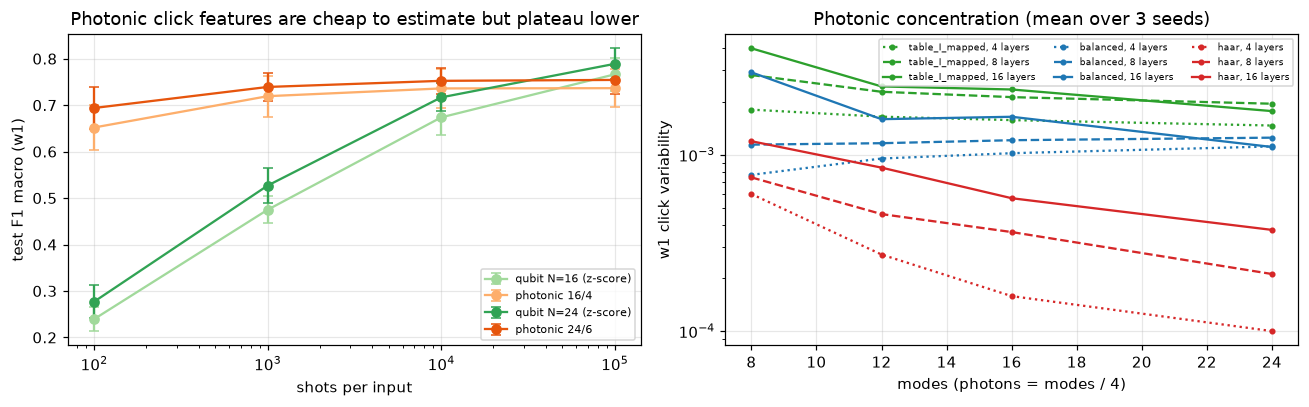

variability ratio 8 modes / 24 modes (how much it falls):


n_layers,4,8,16
setting,,,
balanced,0.69,0.91,2.65
haar,5.98,3.53,3.18
table_I_mapped,1.23,1.45,2.27


In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for system in ("qubit N=16 (z-score)", "photonic 16/4", "qubit N=24 (z-score)", "photonic 24/6"):
    curve = frame("landsat_qelm", system, "shots").groupby("shots").f1_macro.agg(["mean", "std"])
    axes[0].errorbar(curve.index, curve["mean"], yerr=curve["std"], marker="o", capsize=3, color=COLORS[system], label=system)
axes[0].set_xscale("log"); axes[0].set_xlabel("shots per input"); axes[0].set_ylabel("test F1 macro (w1)")
axes[0].set_title("Photonic click features are cheap to estimate but plateau lower"); axes[0].legend(fontsize=7)

conc_ph = pd.DataFrame(EVIDENCE["concentration"]["photonic"]["records"])
for setting, color in (("table_I_mapped", "tab:green"), ("balanced", "tab:blue"), ("haar", "tab:red")):
    for layers, style in zip(sorted(conc_ph.n_layers.unique()), (":", "--", "-")):
        sub = conc_ph[(conc_ph.setting == setting) & (conc_ph.n_layers == layers)].groupby("n_modes").w1_variability_mean.mean()
        axes[1].plot(sub.index, sub.values, style, marker="o", ms=3, color=color, label=f"{setting}, {layers} layers")
axes[1].set_yscale("log"); axes[1].set_xlabel("modes (photons = modes / 4)"); axes[1].set_ylabel("w1 click variability")
axes[1].set_title("Photonic concentration (mean over 3 seeds)"); axes[1].legend(fontsize=6, ncol=3)
plt.tight_layout(); plt.show()
mean_var = conc_ph.groupby(["setting", "n_layers", "n_modes"]).w1_variability_mean.mean().unstack()
print("variability ratio 8 modes / 24 modes (how much it falls):")
(mean_var[8] / mean_var[24]).unstack().round(2)

In [35]:
hardware = EVIDENCE["landsat_qelm"]["photonic 24/6"]["hardware"]
fields = {**hardware, "shots": "multinomial pair click marginals, 1e5 headline (1e2–1e5 sweep)",
          "loss / noise": "lossless, indistinguishable photons, no dark counts",
          "gradients": "none (fixed reservoir, closed-form ridge)",
          "seeds": "5 splits x 3 reservoirs x 3 shot draws",
          "wall-clock (laptop CPU)": "Landsat 16/4: 1 min 22 s; 24/6: 44 min 30 s"}
pd.Series(fields, name="hardware-aware setting (simulated)").to_frame()

,hardware-aware setting (simulated)
computation_space,FOCK
detector_model,"threshold (ideal, every mode)"
encoding,beam-splitter angle theta = angle_scale * inpu...
input_state,"[1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, ..."
measurement_strategy,MeasurementStrategy.probs(FOCK) with threshold...
n_layers,36
n_modes,24
n_photons,6
postselection,none
simulator,MerLin analytic simulation (CPU)


**Observation.**

- On Landsat the photonic reservoir lands within the pre-declared tolerance: −0.047 (16/4,
  narrowly) and −0.033 (24/6).
- On NARMA it is within 10 %, with the memory edge at $n = L$.
- Eigentasks again add nothing.
- Click features reach F1 0.65 with only 100 shots (qubit: 0.24) but plateau lower.
- Haar variability falls 3–6× from 8 to 24 modes at every depth. The mapped Table I brickwall
  falls only 1.2–1.5× at 4–8 layers, and 2.3× at 16 layers, and stays 3–15× above Haar.

**Inference.** The paper's central idea, a structured, weakly mixing reservoir that concentrates
far more slowly than a random one, has a photonic counterpart in MerLin. At 16 layers the mapped
brickwall also loses variability with size, so "avoids concentration" holds only at shallow
depth.

**Remaining uncertainty.** Ideal photonics only: loss, distinguishability and detector efficiency
are not modelled. Table I was transferred, not re-optimised for photons. The MerLin margins over
the tanh baseline (§8) are small and measured against an untuned bandwidth.

**Photonic verdict: feasible and behaviour-preserving in simulation, with no accuracy advantage.**

## 12. Claim-level conclusion

These outcomes are kept separate:

- **The software executes:** yes; the live runs in §6 and §11.2 reproduce stored full runs exactly.
- **The method solves the tasks:** yes. Landsat F1 is 0.72–0.81 (Pauli and eigentask readouts)
  against about 0.17 for random guessing; the NARMA
  memory edge is visible.
- **The paper's metrics reproduce:** Landsat with z-score inputs at 24 qubits (§7.3); the shot and
  training-size curves (§7.4); Fig. 2 (§7.1); Fig. 3a at ≤ 24 qubits (§7.2).
- **The paper's explanation survives controls:** the regime and concentration story does (§7.1,
  §9.4); the eigentask / NSR story does not at ≤ 24 qubits (§9.1–9.2).
- **The method beats a fair baseline:** no. A random feature map of the same size, with the same
  readout, ties or beats it (§8).

### 1. What reproduced

- **C1:** Table I near the Pareto front at 6–12 qubits (§7.1). Fig. 2b at 8 qubits misses narrowly.
- **C2:** Table I transfers without retuning across 8–24 qubits and from NARMA to Landsat
  (§7.2, §7.3).
- **C5:** F1 rises with shots and with training size, matching Fig. 3b/3c with z-score inputs
  (§7.4).
- **C7:** the NARMA memory edge sits at n ≈ N/2 (§7.2).
- **C8, qualitatively, N ≤ 16:** Table I keeps 2–7× more output variability than a scrambling
  circuit (§9.4).
- **The C4 accuracy level:** 0.79–0.81 F1 at 24 qubits with z-score inputs, Pauli and eigentask
  readouts (§7.3), and clearly
  above ridge on raw features (§8).

### 2. What did not reproduce

- **C3:** eigentask readouts, NSR scaling and the NSR cutoff give no gain (§9.1, bootstrap in §10).
- **C6:** there is no F1 optimum near λ = 1; F1 rises up to no-cut (§9.2).
- **C4 "competitive":** the QELM is not above a classical random-feature map with the same number
  of features and the same readout (§8).

### 3. What remains unresolved

- Whether hardware noise at 124 qubits makes the eigentask selection useful (§9.1).
- The paper's unpublished input scaling and Landsat subset (§9.3).
- Whether a validation-tuned random-feature bandwidth closes the small-dimension MerLin margins
  (§8).

### 4. What was not attempted

- The 72- and 124-qubit hardware runs: no QPU, and not exactly simulable.
- C9, energy-price forecasting: the paper names no data source.
- Hardware noise models.

### 5. Reproduction verdict

**Partially reproduced, at reduced scale in simulation.**

- The regime and transfer claims (C1, C2, C5, C7, C8) hold.
- The readout-engineering claims (C3, C6) do not hold at ≤ 24 qubits.
- The competitiveness claim (C4) holds only against raw-feature baselines.
- No quantum advantage is claimed by the paper or found here.

### 6. Extension and photonic verdict

- **Fair baselines (§8):** a dimension-matched classical random-feature map is as good as or
  better than the qubit QELM on Landsat and NARMA.
- **MerLin adaptation (§11):** `PARTIAL_MERLIN_TRANSLATION`. It is feasible and preserves the
  qualitative behaviour (much slower concentration than a Haar interferometer, memory edge,
  accuracy within 0.05 F1 of the qubit model) in ideal simulation.
  - It is cheap in shots.
  - It shows no accuracy advantage.
  - It has not been tested with realistic loss or on hardware.

**Limitations in one place:**

- reduced size (16–24 qubits instead of 124);
- exact simulation without hardware noise;
- our own Landsat subset and split;
- an unstated input scaling, for which both readings are reported;
- our own search ranges and budget for E1, with one search seed;
- untuned random-feature baselines;
- ideal photonics.

Details are in `README.md` (Limitations) and `INSIGHTS.md`.